# v16 — 문헌 근거로 재설계한 train 전용 EDA·전처리
50편의 검토 근거는 LITERATURE_REVIEW_AND_PREPROCESSING_V16.md에 기록합니다. test/sample 접근은 차단합니다. 기존 홀드아웃은 평가하지 않으며 EDA도 개발 환자로 제한합니다. 논문의 정확한 재현과 제한된 입력에 대한 자체 적응을 구분합니다. 외부 환자 데이터는 추가하지 않습니다.

In [1]:
import os,sys,re,json,pickle,cloudpickle,hashlib,platform,time,copy,warnings
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
from scipy import sparse
from scipy.special import softmax
from sklearn.base import BaseEstimator,TransformerMixin,clone
from sklearn.feature_extraction import DictVectorizer
from sklearn.feature_selection import chi2,f_classif
from sklearn.preprocessing import StandardScaler,MaxAbsScaler
from sklearn.multiclass import OneVsRestClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import f1_score,accuracy_score,classification_report,confusion_matrix
from lightgbm import LGBMClassifier
from threadpoolctl import threadpool_limits
from IPython.display import display,FileLink
threadpool_limits(2)
SEED=42
forbidden_attempts16=[]
def forbid_inference16(event,args):
 if event=='open' and args and isinstance(args[0],(str,bytes,os.PathLike)) and Path(os.fsdecode(args[0])).name in {'test.csv','sample_submission.csv'}:
  forbidden_attempts16.append(str(args[0]));raise RuntimeError('Inference data access is forbidden in v16')
sys.addaudithook(forbid_inference16)
roots=[Path.cwd(),*Path.cwd().parents]
REPO=next((p for p in roots if (p/'data/train.csv').is_file()),None)
if REPO is None:raise FileNotFoundError('data/train.csv가 필요합니다.')
DATA=REPO/'data';WORK=REPO/'models'/'혜진' if (REPO/'models'/'혜진').is_dir() else REPO
OUT=WORK/'artifacts'/'v16';OUT.mkdir(parents=True,exist_ok=True)
# Inference files and submission directory are intentionally not used.
os.environ['MPLCONFIGDIR']=str(OUT/'.mplconfig')
train=pd.read_csv(DATA/'train.csv')
genes=[c for c in train if c not in ['ID','SUBCLASS']]
assert train.ID.is_unique
y=train.SUBCLASS.to_numpy();labels=np.sort(np.unique(y));yi=np.searchsorted(labels,y);NC=len(labels)
X=train[genes];groups=pd.util.hash_pandas_object(X,index=False).to_numpy()
dev,hold=next(StratifiedGroupKFold(5,shuffle=True,random_state=SEED).split(X,y,groups))
folds=list(StratifiedGroupKFold(3,shuffle=True,random_state=SEED+1).split(X.iloc[dev],y[dev],groups[dev]))
assert not set(groups[dev]).intersection(groups[hold])
for a,b in folds:assert not set(groups[dev[a]]).intersection(groups[dev[b]])
pd.DataFrame({'ID':train.ID,'split':np.where(np.isin(np.arange(len(train)),hold),'holdout','development'),'group':groups.astype(str)}).to_csv(OUT/'split_manifest.csv',index=False)
print('TRAIN ONLY',train.shape,'Dev/holdout',len(dev),len(hold),'OUT',OUT,flush=True)

from sklearn.neural_network import MLPClassifier
from sklearn.feature_extraction.text import TfidfTransformer
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier


TRAIN ONLY (6201, 4386) Dev/holdout 4960 1241 OUT /Users/mac/project/cancer_project/artifacts/v16


In [2]:
GROUPS = {
 'p53_cellcycle': 'TP53 RB1 CDKN2A CDKN2B CDK4 CDK6 CCND1 ATM CHEK2'.split(),
 'rtk_ras_mapk': 'EGFR ERBB2 ERBB3 KRAS NRAS HRAS BRAF NF1 MAP2K1 MAP2K2 KIT PDGFRA FGFR2 FGFR3'.split(),
 'pi3k_mtor': 'PIK3CA PIK3R1 PTEN AKT1 MTOR TSC1 TSC2 STK11'.split(),
 'dna_repair': 'BRCA1 BRCA2 PALB2 ATM ATR CHEK2 MLH1 MSH2 MSH6 PMS2 POLE POLD1'.split(),
 'chromatin': 'ARID1A ARID1B ARID2 PBRM1 SMARCA4 BAP1 SETD2 KMT2A KMT2C KMT2D ATRX'.split(),
 'wnt': 'APC CTNNB1 AXIN1 AXIN2 RNF43'.split(),
 'metabolism': 'IDH1 IDH2 SDHB SDHC SDHD FH VHL'.split(),
}

def kind(token):
 if 'fs' in token.lower(): return 'frameshift'
 if '*' in token: return 'stop'
 if 'del' in token.lower(): return 'deletion'
 if 'ins' in token.lower(): return 'insertion'
 m = re.fullmatch(r'([A-Z])(\d+)([A-Z])', token)
 if m: return 'synonymous' if m[1] == m[3] else 'substitution'
 return 'other'

class MutationFeatures(BaseEstimator, TransformerMixin):
 def __init__(self, mode='full', min_df=3):
  self.mode = mode
  self.min_df = min_df

 def dictionaries(self, X):
  genes = list(X.columns)
  for row in X.itertuples(index=False, name=None):
   d = {}; counts = {}; burden = 0; events = 0; positions = []
   changed = set()
   for gene, value in zip(genes, row):
    if value is None or str(value) in ('nan', '', '<NA>'):
     d['missing:' + gene] = 1; continue
    if value == 'WT': continue
    changed.add(gene); burden += 1; d['gene:' + gene] = 1
    if self.mode == 'binary': continue
    tokens = str(value).split()
    for raw_token in tokens:
     token = re.sub(r'^([A-Z]\d+)X$', r'\1*', raw_token)
     events += 1; typ = kind(token); counts[typ] = counts.get(typ, 0) + 1
     d['variant:' + gene + ':' + token] = 1
     d['type:' + gene + ':' + typ] = 1
     m = re.search(r'\d+', token)
     if m:
      position = int(m[0]); positions.append(position)
      d['position:' + gene + ':' + str(position)] = 1
   if self.mode == 'full':
    d['numeric:log_mutated_genes'] = np.log1p(burden)
    d['numeric:log_events'] = np.log1p(events)
    d['numeric:multi_event_excess'] = np.log1p(max(0, events-burden))
    for typ in ['frameshift','stop','deletion','insertion','synonymous','substitution','other']:
     d['numeric:log_' + typ] = np.log1p(counts.get(typ,0))
     d['numeric:fraction_' + typ] = counts.get(typ,0)/max(events,1)
    d['numeric:log_mean_position'] = np.log1p(np.mean(positions)) if positions else 0.
    for name, members in GROUPS.items():
     d['module:' + name] = np.log1p(len(changed.intersection(members)))
   yield d

 def fit(self, X, y=None):
  self.genes_ = list(X.columns)
  self.vectorizer_ = DictVectorizer(dtype=np.float32)
  matrix = self.vectorizer_.fit_transform(self.dictionaries(X))
  names = self.vectorizer_.get_feature_names_out()
  self.keep_ = (np.asarray((matrix != 0).sum(axis=0)).ravel() >= self.min_df) | np.array([s.startswith(('numeric:', 'module:')) for s in names])
  self.feature_names_ = names[self.keep_]
  return self

 def transform(self, X):
  missing = set(self.genes_) - set(X.columns)
  if missing: raise ValueError('Missing gene columns: ' + str(sorted(missing)[:10]))
  return sparse.csr_matrix(self.vectorizer_.transform(self.dictionaries(X[self.genes_]))[:, self.keep_])

 def get_feature_names_out(self, input_features=None): return self.feature_names_
def canon(t):
 t=t.strip().removeprefix('p.');t=re.sub(r'(?<=\d)X$','*',t)
 return re.sub(r'^([A-Z]\d+)(?:[A-Z*]+)?fs.*$',r'\1fs',t)
def aa_change(t):
 m=re.fullmatch(r'([A-Z])\d+([A-Z*])',t)
 if m:return m[1]+'>'+m[2]
 m=re.match(r'([A-Z])\d+',t)
 if m:
  for suffix in ['fs','del','ins']:
   if suffix in t:return m[1]+'>'+suffix
 return None

def parse_events(frame):
 names=list(frame.columns);result=[]
 for row in frame.itertuples(index=False,name=None):
  result.append([(g,tuple(sorted(set(canon(t) for t in v.split())))) for g,v in zip(names,row) if isinstance(v,str) and v!='WT'])
 return result

class EvidenceEncoder:
 def __init__(self,unknown=1.,silent=1.,support=2):self.unknown=unknown;self.silent=silent;self.support=support
 def fit(self,events):
  self.token_df={};self.change_df={}
  if self.unknown<1:
   tokens=Counter();changes=Counter()
   for row in events:
    for g,ts in row:
     tokens.update((g,t) for t in ts)
     changes.update(set((g,a) for t in ts if (a:=aa_change(t)) is not None))
   self.token_df={k:v for k,v in tokens.items() if v>=self.support}
   self.change_df={k:v for k,v in changes.items() if v>=self.support}
  return self
 def transform(self,events,training=False,exclude_events=None):
  result=[]
  for row_number,row in enumerate(events):
   own=exclude_events[row_number] if exclude_events is not None else (row if training else [])
   own_tokens={(gg,tt) for gg,tts in own for tt in tts}
   own_changes={(gg,ac) for gg,tts in own for tt in tts if (ac:=aa_change(tt)) is not None}
   d={};gene_weights={};type_sums=Counter();non_syn=0.;trunc=0.;multikind=0
   for g,ts in row:
    types={};gene=0.;known_gene=False
    for t in ts:
     typ=kind(t);a=aa_change(t)
     known=self.token_df.get((g,t),0)-int((g,t) in own_tokens)>=self.support
     known_aa=a is not None and self.change_df.get((g,a),0)-int((g,a) in own_changes)>=self.support
     if typ=='synonymous':w=self.silent
     elif known or typ in ['stop','frameshift','deletion','insertion']:w=1.
     elif known_aa:w=max(self.unknown,.75)
     else:w=self.unknown
     if w<=0:continue
     gene=max(gene,w);types[typ]=max(types.get(typ,0),w)
     d['variant:'+g+':'+t]=max(d.get('variant:'+g+':'+t,0),w)
     m=re.search(r'\d+',t)
     if m:d['position:'+g+':'+m[0]]=max(d.get('position:'+g+':'+m[0],0),w)
     if a:d['aa:'+g+':'+a]=max(d.get('aa:'+g+':'+a,0),w)
     if known and typ!='synonymous':known_gene=True
    if gene<=0:continue
    d['gene:'+g]=gene;gene_weights[g]=gene
    for typ,w in types.items():d['type:'+g+':'+typ]=w;type_sums[typ]+=w
    if known_gene:d['supported:'+g]=1.
    non_syn+=max([w for k,w in types.items() if k!='synonymous'] or [0.])
    trunc+=max([w for k,w in types.items() if k in ['stop','frameshift','deletion','insertion']] or [0.])
    multikind+=len(types)>1
   n=len(row)
   d['numeric:log_raw_genes']=np.log1p(n)
   d['numeric:log_effective_genes']=np.log1p(sum(gene_weights.values()))
   d['numeric:log_nonsyn_genes']=np.log1p(non_syn)
   d['numeric:log_trunc_genes']=np.log1p(trunc)
   d['numeric:log_multikind_genes']=np.log1p(multikind)
   for typ in ['synonymous','substitution','stop','frameshift','deletion','insertion','other']:
    d['numeric:gene_fraction_'+typ]=type_sums[typ]/max(n,1)
   for name,gs in GROUPS.items():d['module:'+name]=np.log1p(sum(gene_weights.get(g,0) for g in gs))
   result.append(d)
  return result

events=parse_events(X)
legacy_records=list(MutationFeatures(mode='full').dictionaries(X))
assert canon('R213X')=='R213*' and canon('K16Rfs')=='K16fs'
assert aa_change('R132H')==aa_change('R140H')=='R>H'
print('Parsed rows:',len(events),'Normalization examples passed')


Parsed rows: 6201 Normalization examples passed


In [3]:
# P43: HGVS 2016 principles; this is a conservative dataset parser, not a full HGVS validator.
AA16=set('ACDEFGHIKLMNPQRSTVWY');THREE16=dict(zip(['Ala','Arg','Asn','Asp','Cys','Gln','Glu','Gly','His','Ile','Leu','Lys','Met','Phe','Pro','Ser','Thr','Trp','Tyr','Val','Ter','Xaa'],list('ARNDCQEGHILKMFPSTWYV')+['*','X']))
# Each event: key, kind, position, components(position,ref,alt,kind), flags, fs_stop_distance.
def parse_token16(raw):
 s=str(raw).strip();core=s[2:] if s.startswith('p.') else s;uncertain=core.startswith('(') and core.endswith(')');core=core[1:-1] if uncertain else core
 if re.match('^(?:'+'|'.join(THREE16)+')[0-9]+',core):core=re.sub('|'.join(THREE16),lambda m:THREE16[m[0]],core)
 key=('uncertain|' if uncertain else '')+core;flags=['uncertain'] if uncertain else [];pos=None;parts=();dist=None;kind='unparsed'
 def effect(a,b):
  if a=='*' and b=='*':return 'stop_retained'
  if a=='*':return 'stop_lost' if b in AA16 else 'ambiguous_residue'
  if b=='*':return 'stop_gained' if a in AA16 else 'ambiguous_residue'
  if a not in AA16 or b not in AA16:return 'ambiguous_residue'
  return 'synonymous' if a==b else 'missense'
 m=re.fullmatch(r'([A-Z*])([1-9][0-9]*)([A-Z*])',core)
 if m:
  a,p,b=m.groups();pos=int(p);kind=effect(a,b);parts=((pos,a,b,kind),)
  if 'X' in [a,b]:flags.append('ambiguous_X')
 else:
  m=re.fullmatch(r'([1-9][0-9]*)_([1-9][0-9]*)([A-Z*]+)>([A-Z*]+)',core)
  if m:
   start,end,ref,alt=m.groups();start=int(start);end=int(end);pos=start;span=end-start+1
   if span>0 and span==len(ref)==len(alt) and all(a in AA16 or a=='*' for a in ref+alt):
    parts=tuple((start+j,a,b,effect(a,b)) for j,(a,b) in enumerate(zip(ref,alt)));kind='synonymous_block' if all(a==b for a,b in zip(ref,alt)) else 'block_change';flags.append('resolved_equal_length_block')
   else:kind='complex_range';flags.append('unresolved_range')
  elif 'fs' in core:
   kind='frameshift';m=re.match(r'([A-Z*]+)([1-9][0-9]*)',core);pos=int(m[2]) if m else None;m=re.search(r'fs(?:\*|Ter)([1-9][0-9]*)$',core);dist=int(m[1]) if m else None
  elif 'delins' in core:kind='delins'
  elif 'del' in core:kind='deletion'
  elif 'ins' in core:kind='insertion'
  elif 'dup' in core:kind='duplication'
  elif 'ext' in core:kind='extension'
  elif core=='=':kind='no_change_unspecified'
  elif re.fullmatch(r'[A-Z*]+[1-9][0-9]*',core):kind='incomplete';flags.append('missing_alternate')
  if pos is None:
   # Protein coordinate only: do not mistake fs termination distance for the affected residue.
   m=re.match(r'(?:[A-Z*]+)?([1-9][0-9]*)',core);pos=int(m[1]) if m else None
 return (key,kind,pos,parts,tuple(flags),dist)

def parse_rows16(frame):
 cols=list(frame.columns);cache={};rows=[]
 for row in frame.itertuples(index=False,name=None):
  mutations=[];missing=[];raw_n=0;duplicates=0
  for gene,value in zip(cols,row):
   if value is None or pd.isna(value) or (isinstance(value,str) and not value.strip()):missing.append(gene);continue
   if str(value).strip()=='WT':continue
   tokens=str(value).split();raw_n+=len(tokens);unique=list(dict.fromkeys(tokens));duplicates+=len(tokens)-len(unique);events=[]
   for token in unique:
    if token not in cache:cache[token]=parse_token16(token)
    events.append(cache[token])
   mutations.append((gene,tuple(events)))
  rows.append({'mutations':tuple(mutations),'missing':tuple(missing),'raw_tokens':raw_n,'duplicate_tokens':duplicates})
 return rows

FIXTURES16=[('R132H','missense',132),('R132R','synonymous',132),('R213*','stop_gained',213),('*363*','stop_retained',363),('*213Q','stop_lost',213),('K16Rfs*23','frameshift',16),('1_2FS>FS','synonymous_block',1),('483_484MP>IA','block_change',483),('10_12AAA>DD','complex_range',10),('490del','deletion',490),('p.(Arg123His)','missense',123),('R123X','ambiguous_residue',123),('A391','incomplete',391),('FS','unparsed',None),('G12delinsAA','delins',12)]
for token,expected_kind16,expected_pos16 in FIXTURES16:
 result=parse_token16(token);assert result[1]==expected_kind16 and result[2]==expected_pos16,(token,result)
assert parse_token16('K16Rfs*23')[5]==23
assert parse_token16('1_2FS>FS')[3]==((1,'F','F','synonymous'),(2,'S','S','synonymous'))
assert 'uncertain' in parse_token16('p.(Arg123His)')[4]
assert parse_rows16(pd.DataFrame({'G':['WT',None,'R1H R1H']}))[1]['missing']==('G',)
assert parse_rows16(pd.DataFrame({'G':['WT',None,'R1H R1H']}))[2]['duplicate_tokens']==1
print('P43 annotation safety fixtures passed:',len(FIXTURES16),flush=True)
# P25-P40: small, explicit gene subsets in the publications, not whole pathways or diagnostic rules.
PANELS16={
 'P25_breast':('TP53','PIK3CA','GATA3','MAP3K1'),
 'P26_colorectal':('APC','TP53','SMAD4','PIK3CA','KRAS','ARID1A','SOX9','FAM123B','POLE','MLH1'),
 'P27_glioma':('IDH1','IDH2','TP53','ATRX','CIC','FUBP1','NOTCH1'),
 'P29_gbm':('EGFR','PDGFRA'),
 'P30_renal':('VHL','PBRM1','SETD2','ARID1A','SMARCA4'),
 'P31_papillary_renal':('MET','SETD2','FH'),
 'P32_ovarian':('TP53','NF1','BRCA1','BRCA2','RB1','CDK12'),
 'P33_uterine':('TP53','PTEN','CTNNB1','PIK3CA','ARID1A','KRAS','ARID5B','POLE'),
 'P34_thyroid':('BRAF','EIF1AX','PPM1D','CHEK2'),
 'P35_prostate':('SPOP','FOXA1','IDH1'),
 'P36_lung_ad':('RIT1','MGA','EGFR','RBM10','NF1','MET','ERBB2'),
 'P37_lung_scc':('TP53','HLA-A','NFE2L2','KEAP1','CDKN2A','RB1'),
 'P38_melanoma':('BRAF','NRAS','HRAS','KRAS','NF1','KIT'),
 'P39_gastric':('PIK3CA','RHOA'),
 'P40_headneck':('PIK3CA','TRAF3','TP53','CDKN2A','HRAS','CASP8','NOTCH1','NSD1','AJUBA','FAT1','NFE2L2')}
print('Literature panel subsets:',len(PANELS16),'(external biological prior; no external patient data)',flush=True)


P43 annotation safety fixtures passed: 15
Literature panel subsets: 15 (external biological prior; no external patient data)


In [4]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.feature_selection import chi2
from sklearn.preprocessing import MaxAbsScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import ExtraTreesClassifier
from scipy import sparse
from collections import Counter
import copy
VIEWS16=['legacy_raw','hierarchical','rare_backoff','rare_backoff_panels']
# Literature-derived panel snapshots are explicit priors, not learned class labels.
class Preprocess16:
 def __init__(self,view,min_df=3,k=4096):self.view=view;self.min_df=min_df;self.k=k
 def fit(self,rows,target):
  self.df=Counter((g,e[0]) for row in rows for g,evs in row['mutations'] for e in {e[0]:e for e in evs}.values())
  records=self.records(rows,training=True);self.vec=DictVectorizer(dtype=np.float32);a=self.vec.fit_transform(records);names=self.vec.get_feature_names_out();support=np.asarray((a!=0).sum(0)).ravel();keep=(support>=self.min_df)|np.array([s.startswith(('num:','module:','numeric:','panel:')) for s in names]);self.keep=np.flatnonzero(keep);a=a[:,self.keep]
  with warnings.catch_warnings():
   warnings.simplefilter('ignore');scores=np.nan_to_num(chi2(a,target)[0],nan=0,posinf=0,neginf=0)
  self.cols=np.sort(np.argsort(-scores,kind='stable')[:min(self.k,a.shape[1])]);self.names=names[self.keep[self.cols]];selected=a[:,self.cols];self.scale=MaxAbsScaler().fit(selected);self.residual_weights=np.ones(len(self.names),np.float32)
  if self.view.startswith('rare_backoff'):
   for j,name in enumerate(self.names):
    if name.startswith('variant:'):
     _,gene,key=name.split(':',2);n=self.df.get((gene,key),0);self.residual_weights[j]=n/(n+5.)
  return self
 def records(self,rows,training=False):
  # legacy records were computed pointwise using the frozen v6 raw encoder.
  if self.view=='legacy_raw':return [r['legacy'] for r in rows]
  result=[]
  for row in rows:
   d={};types=Counter();gene_effects={};n=0;rare=0;new=0;uncertain=0;incomplete=0;components=0;ambiguous_x=0
   for g,evs in row['mutations']:
    evs=list({e[0]:e for e in evs}.values());d['gene:'+g]=1.;d['gene_event_count:'+g]=np.log1p(len(evs));local=Counter();bin64=set();bin256=set()
    for key,kind,pos,parts,flags,fsdist in evs:
     n+=1;support=max(0,self.df.get((g,key),0)-(int(training)));israre=support<3;rare+=israre;new+=support==0;uncertain+='uncertain' in flags;incomplete+=kind in ['incomplete','unparsed','complex_range'];ambiguous_x+='ambiguous_X' in flags
     effects=[p[3] for p in parts] or [kind];types.update(effects);local.update(effects);d['format:'+g+':'+kind]=1.;components+=len(parts)
     if self.df.get((g,key),0)>=3:
      d['variant:'+g+':'+key]=1.
     if self.view.startswith('rare_backoff'):
      bucket='rare' if israre else 'supported';d[bucket+'_gene:'+g]=d.get(bucket+'_gene:'+g,0)+1
     for p,a,b,effect in parts:
      d['aa_meta:'+g+':'+a+'>'+b]=d.get('aa_meta:'+g+':'+a+'>'+b,0)+1;d['aa_global:'+a+'>'+b]=d.get('aa_global:'+a+'>'+b,0)+1
     if pos is not None:bin64.add((pos-1)//64);bin256.add((pos-1)//256)
     # Absolute protein bins are an engineering heuristic, not genomic bins or biological domains.
     if fsdist is not None:d['fs_stop_distance:'+g]=np.log1p(fsdist)
    for kind,count in local.items():d['effect:'+g+':'+kind]=np.log1p(count)
    for b in bin64:d[f'protein_bin64:{g}:{b}']=1.
    for b in bin256:d[f'protein_bin256:{g}:{b}']=1.
    gene_effects[g]=local
   for name,count in [('observed_genes',len(row['mutations'])),('unique_events',n),('raw_tokens',row['raw_tokens']),('duplicate_tokens',row['duplicate_tokens']),('missing_genes',len(row['missing'])),('uncertain_events',uncertain),('incomplete_events',incomplete),('ambiguous_X',ambiguous_x),('resolved_components',components)]:d['num:log_'+name]=np.log1p(count)
   for kind in ['synonymous','missense','stop_gained','stop_lost','stop_retained','frameshift','deletion','insertion','delins','complex_range','incomplete','unparsed','ambiguous_residue']:
    d['num:log_'+kind]=np.log1p(types[kind]);d['num:fraction_'+kind]=types[kind]/max(sum(types.values()),1)
   if self.view.startswith('rare_backoff'):d['num:log_rare_events']=np.log1p(rare);d['num:rare_fraction']=rare/max(n,1);d['num:log_unseen_events']=np.log1p(new)
   if self.view.endswith('panels'):
    observed=set(gene_effects)
    for panel,gs in PANELS16.items():
     count=len(observed.intersection(gs));d['panel:'+panel+':mutated_genes']=np.log1p(count)
     flags=sum(bool(set(gene_effects.get(g,{})).intersection({'stop_gained','frameshift','deletion','delins'})) for g in gs);d['panel:'+panel+':truncation_notation_genes']=np.log1p(flags)
   result.append(d)
  return result
 def transform(self,rows,training=False):
  a=self.vec.transform(self.records(rows,training=training));a=a[:,self.keep][:,self.cols];return sparse.csr_matrix(self.scale.transform(a).multiply(self.residual_weights),dtype=np.float32)

class Model16:
 def __init__(self,view,algo):self.view=view;self.algo=algo
 def fit(self,rows,target):
  self.pre=Preprocess16(self.view).fit(rows,target);a=self.pre.transform(rows,training=True)
  self.est=LogisticRegression(C=.1,class_weight='balanced',max_iter=1200) if self.algo=='lr' else ExtraTreesClassifier(n_estimators=200,max_depth=20,min_samples_leaf=2,max_features='sqrt',class_weight='balanced',n_jobs=2,random_state=16016)
  self.est.fit(a,target);return self
 def predict_proba(self,rows):
  p=self.est.predict_proba(self.pre.transform(rows));out=np.zeros((len(rows),NC),np.float64);out[:,self.est.classes_.astype(int)]=p;return out
 def predict_frame(self,frame):
  rows=parse_rows16(frame[GENES16]);legacy=EvidenceEncoder(1.,1.).fit([]).transform(parse_events(frame[GENES16]))
  for row,d in zip(rows,legacy):row['legacy']=d
  return self.predict_proba(rows)


In [5]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import f1_score,accuracy_score,classification_report
from threadpoolctl import threadpool_limits
threadpool_limits(2)
# Predeclare the small comparison. Inner CV selects preprocessing; no outer labels enter fitting.
PROTOCOL16={'views':VIEWS16,'lr_C':.1,'k':4096,'min_df':3,'outer_folds':3,'outer_seed':16016,'inner_folds':2,'inner_seed_base':16017,'tree_params':{'n_estimators':200,'max_depth':20,'min_samples_leaf':2},'inner_selection':'view for fixed LR only','no_test':True,'no_holdout_scoring':True,'external_patient_data':False,'panel_membership':'fixed article-derived biological prior','exact_method_replication':False}
(OUT/'protocol.json').write_text(json.dumps(PROTOCOL16,indent=2))
GENES16=list(genes);parsed16=parse_rows16(X);legacy16=EvidenceEncoder(1.,1.).fit([]).transform(parse_events(X))
for row,d in zip(parsed16,legacy16):row['legacy']=d
# All grouping is pointwise and label-free. Preserve the old holdout; exclude any dev-side collisions.
keys16=[]
for row in parsed16:
 signature=(tuple(sorted((g,tuple(sorted(set(e[0] for e in ev)))) for g,ev in row['mutations'])),tuple(sorted(row['missing'])))
 keys16.append(hashlib.sha256(repr(signature).encode()).hexdigest())
keys16=np.array(keys16);raw16=groups.copy();parent16=np.arange(len(train))
def find16(i):
 while parent16[i]!=i:parent16[i]=parent16[parent16[i]];i=parent16[i]
 return i
def union16(a,b):parent16[find16(b)]=find16(a)
# Raw-identical and new canonical-identical profiles are unioned, never split to inflate scores.
for identifiers in [raw16,keys16]:
 first={}
 for i,key in enumerate(identifiers):
  if key in first:union16(first[key],i)
  else:first[key]=i
GROUP16=np.array([find16(i) for i in range(len(train))]);shared16=set(GROUP16[dev]).intersection(GROUP16[hold]);excluded16=dev[np.isin(GROUP16[dev],list(shared16))];DEV16=dev[~np.isin(GROUP16[dev],list(shared16))]
assert not set(GROUP16[DEV16]).intersection(GROUP16[hold])
(OUT/'split_audit.json').write_text(json.dumps({'development_rows':len(DEV16),'old_holdout_rows':len(hold),'excluded_development_rows':excluded16.tolist(),'raw_unique_profiles':len(np.unique(raw16)),'canonical_unique_profiles':len(set(keys16)),'union_groups':len(np.unique(GROUP16)),'holdout_not_scored':True},indent=2))
# EDA is restricted to development patients; no class distributions are learned from the old holdout.
token_audit16=[];rawtokens=Counter(v for i in DEV16 for g,cell in zip(GENES16,X.iloc[i]) if isinstance(cell,str) and cell!='WT' for v in cell.split())
for token,count in rawtokens.items():
 key,parsed_kind16,pos,parts,flags,distance=parse_token16(token);token_audit16.append(dict(raw=token,canonical=key,kind=parsed_kind16,protein_position=pos,component_count=len(parts),flags='|'.join(flags),frame_new_stop_distance=distance,occurrences=count))
pd.DataFrame(token_audit16).to_csv(OUT/'parser_audit_dev.csv',index=False)
eda16=[]
for i in DEV16:
 row=parsed16[i];effects=Counter(kind for g,ev in row['mutations'] for key,kind,pos,parts,flags,d in ev);unique=sum(len({e[0] for e in ev}) for g,ev in row['mutations']);eda16.append(dict(ID=train.ID.iloc[i],SUBCLASS=y[i],mutated_genes=len(row['mutations']),unique_events=unique,raw_tokens=row['raw_tokens'],duplicates=row['duplicate_tokens'],missing=len(row['missing']),frameshift=effects['frameshift'],stop_gained=effects['stop_gained'],stop_retained=effects['stop_retained'],unparsed=effects['unparsed']+effects['incomplete']+effects['complex_range']))
edaf=pd.DataFrame(eda16);edaf.to_csv(OUT/'eda_development_patients.csv',index=False);edaf.groupby('SUBCLASS').agg(patients=('ID','size'),mean_mutated_genes=('mutated_genes','mean'),median_mutated_genes=('mutated_genes','median'),mean_unique_events=('unique_events','mean'),mean_unparsed=('unparsed','mean'),stop_retained=('stop_retained','sum')).to_csv(OUT/'eda_by_class.csv')
marker16=[]
for panel,gs in PANELS16.items():
 for g in gs:
  for label in labels:
   idx=DEV16[y[DEV16]==label];support=sum(any(gg==g for gg,ev in parsed16[i]['mutations']) for i in idx) if g in GENES16 else 0;marker16.append(dict(panel=panel,paper=panel.split('_')[0],gene=g,column_present=g in GENES16,SUBCLASS=label,n=len(idx),mutated_patients=support,fraction=support/max(len(idx),1)))
pd.DataFrame(marker16).to_csv(OUT/'literature_marker_eda.csv',index=False)
outer16=list(StratifiedGroupKFold(3,shuffle=True,random_state=16016).split(X.iloc[DEV16],y[DEV16],GROUP16[DEV16]));results16=[];inner16=[];chosen16=[];P16={(v,a):np.zeros((len(DEV16),NC),np.float32) for v in VIEWS16 for a in ['lr','extra']};nested16=np.zeros((len(DEV16),NC),np.float32)
for fold,(a,b) in enumerate(outer16):
 tr=DEV16[a];va=DEV16[b];assert not set(GROUP16[tr]).intersection(GROUP16[va]);inner_splits=list(StratifiedGroupKFold(2,shuffle=True,random_state=16017+fold).split(X.iloc[tr],y[tr],GROUP16[tr]));iscores={}
 for view in VIEWS16:
  scores=[]
  for j,(ia,ib) in enumerate(inner_splits):
   it=tr[ia];iv=tr[ib];assert not set(GROUP16[it]).intersection(GROUP16[iv]);m=Model16(view,'lr').fit([parsed16[i] for i in it],yi[it]);p=m.predict_proba([parsed16[i] for i in iv]);f=f1_score(yi[iv],p.argmax(1),average='macro',labels=np.arange(NC),zero_division=0);scores.append(f);inner16.append(dict(outer_fold=fold,inner_fold=j,view=view,macro_f1=f))
  iscores[view]=float(np.mean(scores));print('V16 inner',fold,view,round(iscores[view],5),flush=True)
 winner=max(VIEWS16,key=lambda v:iscores[v]);chosen16.append(dict(fold=fold,view=winner,inner_macro_f1=iscores[winner]));print('V16 outer selection frozen',fold,winner,flush=True)
 for view in VIEWS16:
  for algo in ['lr','extra']:
   started=time.time();m=Model16(view,algo).fit([parsed16[i] for i in tr],yi[tr]);p=m.predict_proba([parsed16[i] for i in va]);P16[(view,algo)][b]=p
   if algo=='lr' and view==winner:nested16[b]=p
   results16.append(dict(fold=fold,view=view,algo=algo,macro_f1=f1_score(yi[va],p.argmax(1),average='macro',labels=np.arange(NC),zero_division=0),accuracy=accuracy_score(yi[va],p.argmax(1)),selected_features=len(m.pre.names),seconds=time.time()-started));pd.DataFrame(results16).to_csv(OUT/'outer_fold_results.csv',index=False);print('V16 outer',fold,view,algo,'F1',round(results16[-1]['macro_f1'],5),'seconds',round(time.time()-started,1),flush=True)
 pd.DataFrame(inner16).to_csv(OUT/'inner_selection.csv',index=False);pd.DataFrame(chosen16).to_csv(OUT/'inner_selected_views.csv',index=False);np.savez_compressed(OUT/'oof_probabilities.npz',dev=DEV16,labels=labels,nested_selected=nested16,**{v+'__'+a:p for (v,a),p in P16.items()})
summary16=pd.DataFrame(results16).groupby(['view','algo'])[['macro_f1','accuracy','selected_features']].mean().sort_values('macro_f1',ascending=False);summary16.to_csv(OUT/'comparison.csv');nested_scores16=[f1_score(yi[DEV16[b]],nested16[b].argmax(1),average='macro',labels=np.arange(NC),zero_division=0) for a,b in outer16]
# Final experimental preprocessing recipe comes from inner selections, not the maximum outer score.
votes16=Counter(r['view'] for r in chosen16);finalview16=max(VIEWS16,key=lambda v:(votes16[v],np.mean([r['macro_f1'] for r in inner16 if r['view']==v])));final16=Model16(finalview16,'lr').fit(parsed16,yi)
with (OUT/'cancer_model_v16_experimental.pkl').open('wb') as f:cloudpickle.dump(final16,f)
with (OUT/'preprocessor_v16.pkl').open('wb') as f:cloudpickle.dump(final16.pre,f)
pd.DataFrame({'feature':final16.pre.names}).to_csv(OUT/'final_selected_features.csv',index=False)
metrics16={'nested_selected_lr_fold_f1':nested_scores16,'nested_selected_lr_mean_f1':float(np.mean(nested_scores16)),'nested_selected_lr_pooled_f1':float(f1_score(yi[DEV16],nested16.argmax(1),average='macro',labels=np.arange(NC))),'final_view_from_inner_selection':finalview16,'view_votes':dict(votes16),'old_holdout_scored':False,'test_opened':False,'sample_opened':False,'new_submission_created':False,'external_patient_data_added':False,'outer_grid_max_is_exploratory':True,'data_sha256':hashlib.sha256((DATA/'train.csv').read_bytes()).hexdigest()}
(OUT/'metrics.json').write_text(json.dumps(metrics16,indent=2));print('V16 SUMMARY',summary16.to_string(),flush=True);print('V16 NESTED',metrics16,flush=True)


V16 inner 0 legacy_raw 0.34004
V16 inner 0 hierarchical 0.34602
V16 inner 0 rare_backoff 0.35094
V16 inner 0 rare_backoff_panels 0.35463
V16 outer selection frozen 0 rare_backoff_panels
V16 outer 0 legacy_raw lr F1 0.40099 seconds 1.8
V16 outer 0 legacy_raw extra F1 0.36581 seconds 1.9
V16 outer 0 hierarchical lr F1 0.40229 seconds 4.4
V16 outer 0 hierarchical extra F1 0.37653 seconds 4.4
V16 outer 0 rare_backoff lr F1 0.40399 seconds 4.8
V16 outer 0 rare_backoff extra F1 0.39105 seconds 4.8
V16 outer 0 rare_backoff_panels lr F1 0.40547 seconds 5.5
V16 outer 0 rare_backoff_panels extra F1 0.39406 seconds 5.4
V16 inner 1 legacy_raw 0.3473
V16 inner 1 hierarchical 0.36561
V16 inner 1 rare_backoff 0.3663
V16 inner 1 rare_backoff_panels 0.36657
V16 outer selection frozen 1 rare_backoff_panels
V16 outer 1 legacy_raw lr F1 0.37767 seconds 2.0
V16 outer 1 legacy_raw extra F1 0.32861 seconds 2.0
V16 outer 1 hierarchical lr F1 0.3972 seconds 4.6
V16 outer 1 hierarchical extra F1 0.35826 seconds

## 오프라인 문헌 근거 레지스트리
50편의 출처·직접 작성한 요약·검토 범위를 고정합니다. 논문 원문은 코드 실행 의존성이 아닙니다.

In [6]:
BIBLIO16 = [{'id': 'P01', 'title': 'A deep learning system accurately classifies primary and metastatic cancers using passenger mutation patterns.', 'year': '2020', 'authors': 'Jiao W, Atwal G, Polak P, Karlic R, Cuppen E, PCAWG Tumor Subtypes and Clinical Translation Working Group, Danyi A, de Ridder J, van Herpen C, Lolkema MP, Steeghs N, Getz G, Morris QD, Stein LD, PCAWG Consortium.', 'journal': 'Nature communications', 'doi': '10.1038/s41467-019-13825-8', 'pmid': '32024849', 'pmcid': 'PMC7002586', 'url': 'https://doi.org/10.1038/s41467-019-13825-8', 'primary_fulltext_url': 'https://pmc.ncbi.nlm.nih.gov/articles/PMC7002586/', 'fulltext_downloaded': True, 'scope': '초록 + Somatic mutation feature sets / Neural Network 절', 'finding': 'WGS의 염기 치환 문맥과 유전체 구간별 passenger 분포를 결합한다. 단순 유전자 목록 분류기와 입력 정보가 다르다.', 'use': '변이 종류와 전체 관측 변이량을 분리해 EDA하고, 동의 변이를 근거 없이 제거하지 않는다.', 'limit': 'CSV에는 염기 문맥·염색체·1 Mb 구간이 없다. SBS96, 유전체 분포, 논문 신경망을 재현하지 않았으며 AA 변화는 DNA signature가 아니다.', 'tags': ['EDA-burden', 'M02', 'X01'], 'retrieved_on': '2026-11-10', 'short_author': 'Jiao W'}, {'id': 'P02', 'title': 'Machine learning-based tissue of origin classification for cancer of unknown primary diagnostics using genome-wide mutation features.', 'year': '2022', 'authors': 'Nguyen L, Van Hoeck A, Cuppen E.', 'journal': 'Nature communications', 'doi': '10.1038/s41467-022-31666-w', 'pmid': '35817764', 'pmcid': 'PMC9273599', 'url': 'https://doi.org/10.1038/s41467-022-31666-w', 'primary_fulltext_url': 'https://pmc.ncbi.nlm.nih.gov/articles/PMC9273599/', 'fulltext_downloaded': True, 'scope': '초록 + Extraction of genomic features / Classifier training 절', 'finding': 'CUPLR는 WGS 기반 driver/passenger·구조변이 특징과 암종별 선별, OOF 확률 보정을 사용한다.', 'use': '서로 다른 특징군의 기여를 분리하고 선별을 학습 부분 안에 둔다.', 'limit': '511개 특징과 구조변이·RMD·isotonic calibration은 구현하지 않았다. 동일한 정보가 없는 이 데이터에 논문 성능을 전용하지 않는다.', 'tags': ['M06', 'X01'], 'retrieved_on': '2026-11-10', 'short_author': 'Nguyen L'}, {'id': 'P03', 'title': 'Predicting Cancer Tissue-of-Origin by a Machine Learning Method Using DNA Somatic Mutation Data.', 'year': '2020', 'authors': 'Liu X, Li L, Peng L, Wang B, Lang J, Lu Q, Zhang X, Sun Y, Tian G, Zhang H, Zhou L.', 'journal': 'Frontiers in genetics', 'doi': '10.3389/fgene.2020.00674', 'pmid': '32760423', 'pmcid': 'PMC7372518', 'url': 'https://doi.org/10.3389/fgene.2020.00674', 'primary_fulltext_url': 'https://pmc.ncbi.nlm.nih.gov/articles/PMC7372518/', 'fulltext_downloaded': True, 'scope': '초록 + Feature Selection 절', 'finding': '유전자별 체세포 변이에서 RF 중요도 선별과 로지스틱 분류를 결합했다.', 'use': '복잡한 새 앙상블보다 로지스틱과 트리의 단순 대조 실험으로 전처리 효과를 먼저 비교한다.', 'limit': '논문의 300개 유전자나 보고 정확도를 그대로 가져오지 않는다. 본 실험은 chi2 선별을 매 fold 내부에서 수행한다.', 'tags': ['M06', 'M07'], 'retrieved_on': '2026-11-10', 'short_author': 'Liu X'}, {'id': 'P04', 'title': 'A machine learning framework to trace tumor tissue-of-origin of 13 types of cancer based on DNA somatic mutation.', 'year': '2020', 'authors': 'He B, Dai C, Lang J, Bing P, Tian G, Wang B, Yang J.', 'journal': 'Biochimica et biophysica acta. Molecular basis of disease', 'doi': '10.1016/j.bbadis.2020.165916', 'pmid': '32771416', 'pmcid': None, 'url': 'https://doi.org/10.1016/j.bbadis.2020.165916', 'primary_fulltext_url': None, 'fulltext_downloaded': False, 'scope': '초록', 'finding': 'ICGC의 변이량을 유전자 길이로 정규화한 표현과 RF를 평가했다.', 'use': '유전자 존재 여부 외에 이벤트 수와 관측 변이량을 보존한다.', 'limit': '실제 유전자 길이·시퀀싱 영역이 없으므로 길이 정규화를 재현하지 않는다. 관측 최대 AA 위치를 유전자 길이로 쓰거나 변이 수를 TMB/Mb라고 부르지 않는다.', 'tags': ['M02', 'X02'], 'retrieved_on': '2026-11-10', 'short_author': 'He B'}, {'id': 'P05', 'title': 'Using the "Hidden" genome to improve classification of cancer types.', 'year': '2021', 'authors': 'Chakraborty S, Begg CB, Shen R.', 'journal': 'Biometrics', 'doi': '10.1111/biom.13367', 'pmid': '32914442', 'pmcid': 'PMC8846548', 'url': 'https://doi.org/10.1111/biom.13367', 'primary_fulltext_url': 'https://pmc.ncbi.nlm.nih.gov/articles/PMC8846548/', 'fulltext_downloaded': False, 'scope': '초록 + PMC 검색 색인에 제공된 Model / Prediction / CV 본문', 'finding': '새 환자의 미관측 희귀 변이를 유전자·염기 문맥 메타특징으로 연결하고, 변이 고유 효과를 계층적으로 추정한다.', 'use': '정확한 변이 residual과 유전자·유형·AA 변화 메타특징을 함께 두어 희귀·미관측 변이도 공유 특징에 남게 한다.', 'limit': 'group-lasso 혼합효과 모델의 재현은 아니다. df/(df+5) 감쇠는 자체 휴리스틱이며 염기 문맥 대신 단백질 수준의 가능한 메타특징만 사용한다.', 'tags': ['M03', 'X01'], 'retrieved_on': '2026-11-10', 'short_author': 'Chakraborty S'}, {'id': 'P06', 'title': 'CPEM: Accurate cancer type classification based on somatic alterations using an ensemble of a\xa0random forest and a deep neural network.', 'year': '2019', 'authors': 'Lee K, Jeong HO, Lee S, Jeong WK.', 'journal': 'Scientific reports', 'doi': '10.1038/s41598-019-53034-3', 'pmid': '31729414', 'pmcid': 'PMC6858312', 'url': 'https://doi.org/10.1038/s41598-019-53034-3', 'primary_fulltext_url': 'https://pmc.ncbi.nlm.nih.gov/articles/PMC6858312/', 'fulltext_downloaded': True, 'scope': '초록 + Experimental setup / Feature Construction 절', 'finding': 'CPEM은 유전자별 변이 개수와 여러 genomic 특징을 비교하고 inner/outer CV를 분리했다.', 'use': '유전자별 다중 이벤트를 무조건 1로만 축약하지 않고, 전처리 선택은 inner 그룹 CV에 넣는다.', 'limit': 'CNV·SBS와 RF+DNN 전체를 재현하지 않는다. 본 실험의 주 평가치는 고정 LR의 nested 전처리 선택 과정이며 트리는 별도 대조다.', 'tags': ['M02', 'M06'], 'retrieved_on': '2026-11-10', 'short_author': 'Lee K'}, {'id': 'P07', 'title': 'Predicting cancer type from tumour DNA signatures.', 'year': '2017', 'authors': 'Soh KP, Szczurek E, Sakoparnig T, Beerenwinkel N.', 'journal': 'Genome medicine', 'doi': '10.1186/s13073-017-0493-2', 'pmid': '29183400', 'pmcid': 'PMC5706302', 'url': 'https://doi.org/10.1186/s13073-017-0493-2', 'primary_fulltext_url': 'https://pmc.ncbi.nlm.nih.gov/articles/PMC5706302/', 'fulltext_downloaded': True, 'scope': '초록 + Methods 절', 'finding': '돌연변이만 쓰는 경우와 copy-number를 함께 쓰는 경우의 성능 차이를 보고했다.', 'use': '정보 종류의 한계를 명시하고, 단순 로지스틱·트리 기준선을 남긴다.', 'limit': '다른 암종 수와 accuracy 결과를 현재 26종 Macro F1의 이론적 상한으로 해석하지 않는다. 없는 CNV를 WT 표기로부터 추정하지 않는다.', 'tags': ['M07', 'X01'], 'retrieved_on': '2026-11-10', 'short_author': 'Soh KP'}, {'id': 'P08', 'title': 'Development of Genome-Derived Tumor Type Prediction to Inform Clinical Cancer Care.', 'year': '2020', 'authors': 'Penson A, Camacho N, Zheng Y, Varghese AM, Al-Ahmadie H, Razavi P, Chandarlapaty S, Vallejo CE, Vakiani E, Gilewski T, Rosenberg JE, Shady M, Tsui DWY, Reales DN, Abeshouse A, Syed A, Zehir A, Schultz N, Ladanyi M, Solit DB, Klimstra DS, Hyman DM, Taylor BS, Berger MF.', 'journal': 'JAMA oncology', 'doi': '10.1001/jamaoncol.2019.3985', 'pmid': '31725847', 'pmcid': 'PMC6865333', 'url': 'https://doi.org/10.1001/jamaoncol.2019.3985', 'primary_fulltext_url': 'https://pmc.ncbi.nlm.nih.gov/articles/PMC6865333/', 'fulltext_downloaded': False, 'scope': '구조화 초록', 'finding': '임상 패널의 분자 변이와 유도 특징을 결합하고 별도 외부 코호트에서 평가했다.', 'use': '임상 확률과 모델 점수를 구분하고, 반복 재분할을 독립 외부 검증이라고 부르지 않는다.', 'limit': '외부 환자 데이터·임상 패널·signature·calibration을 가져오지 않았다. 본 데이터의 새로운 임상 성능을 주장하지 않는다.', 'tags': ['M06', 'X01'], 'retrieved_on': '2026-11-10', 'short_author': 'Penson A'}, {'id': 'P09', 'title': 'Mutation-Attention (MuAt): deep representation learning of somatic mutations for tumour typing and subtyping.', 'year': '2023', 'authors': 'Sanjaya P, Maljanen K, Katainen R, Waszak SM, Genomics England Research Consortium, Aaltonen LA, Stegle O, Korbel JO, Pitkänen E.', 'journal': 'Genome medicine', 'doi': '10.1186/s13073-023-01204-4', 'pmid': '37420249', 'pmcid': 'PMC10326961', 'url': 'https://doi.org/10.1186/s13073-023-01204-4', 'primary_fulltext_url': 'https://pmc.ncbi.nlm.nih.gov/articles/PMC10326961/', 'fulltext_downloaded': True, 'scope': '초록 + Preparing MuAt inputs / Evaluating MuAt in sparse data 절', 'finding': '개별 변이의 문맥·위치·주석을 attention 입력으로 사용하며 희소 변이 조건도 평가한다.', 'use': '원문 변이 토큰과 구조화 속성을 함께 보존하고 변이량에 따른 EDA를 한다.', 'limit': 'DNA 3-mer와 유전체 위치가 없어 MuAt attention 입력은 만들 수 없다. 단백질 위치 bin은 자체 특징이지 논문 1 Mb genomic bin이 아니다.', 'tags': ['M01', 'M03', 'X01'], 'retrieved_on': '2026-11-10', 'short_author': 'Sanjaya P'}, {'id': 'P10', 'title': 'Cancer classification and pathway discovery using non-negative matrix factorization.', 'year': '2019', 'authors': 'Zeng Z, Vo AH, Mao C, Clare SE, Khan SA, Luo Y.', 'journal': 'Journal of biomedical informatics', 'doi': '10.1016/j.jbi.2019.103247', 'pmid': '31271844', 'pmcid': 'PMC6697569', 'url': 'https://doi.org/10.1016/j.jbi.2019.103247', 'primary_fulltext_url': 'https://pmc.ncbi.nlm.nih.gov/articles/PMC6697569/', 'fulltext_downloaded': False, 'scope': '초록', 'finding': '유전자 수준으로 변이를 모으고 nsNMF와 SVM을 결합했다. 평가한 설정에서는 count 표현이 annotation score 표현보다 나았다.', 'use': '유전자별 event count를 별도 특징으로 남기고 annotation 점수를 가짜로 만들지 않는다.', 'limit': 'NMF/SVM 파이프라인과 SIFT·PolyPhen·CADD 점수는 구현하지 않았다. 4개 암종의 결과를 현재 과제와 직접 비교하지 않는다.', 'tags': ['M02', 'X03'], 'retrieved_on': '2026-11-10', 'short_author': 'Zeng Z'}, {'id': 'P11', 'title': 'Network-based stratification of tumor mutations.', 'year': '2013', 'authors': 'Hofree M, Shen JP, Carter H, Gross A, Ideker T.', 'journal': 'Nature methods', 'doi': '10.1038/nmeth.2651', 'pmid': '24037242', 'pmcid': 'PMC3866081', 'url': 'https://doi.org/10.1038/nmeth.2651', 'primary_fulltext_url': 'https://pmc.ncbi.nlm.nih.gov/articles/PMC3866081/', 'fulltext_downloaded': True, 'scope': '초록 + Processing of patient mutation profiles / Network smoothing 절', 'finding': '유전자 변이 신호를 외부 네트워크에 확산하고 NMF·consensus clustering으로 아형을 찾는다.', 'use': '희귀한 개별 유전자 신호를 묶는 관점을 참고하되, 본 구현은 명시적 문헌 유전자 패널 합계로만 제한한다.', 'limit': 'PPI·random-walk·NBS를 재현하지 않았다. 원문의 저변이 환자 제외를 따라하지 않고 모든 개발 환자를 평가한다.', 'tags': ['M04', 'EDA-burden', 'X04'], 'retrieved_on': '2026-11-10', 'short_author': 'Hofree M'}, {'id': 'P12', 'title': 'pyNBS: a Python implementation for network-based stratification of tumor mutations.', 'year': '2018', 'authors': 'Huang JK, Jia T, Carlin DE, Ideker T.', 'journal': 'Bioinformatics (Oxford, England)', 'doi': '10.1093/bioinformatics/bty186', 'pmid': '29608663', 'pmcid': 'PMC6084608', 'url': 'https://doi.org/10.1093/bioinformatics/bty186', 'primary_fulltext_url': 'https://pmc.ncbi.nlm.nih.gov/articles/PMC6084608/', 'fulltext_downloaded': False, 'scope': '초록', 'finding': 'pyNBS는 NBS 단계를 모듈화하고 네트워크·파라미터 재현성을 다룬다.', 'use': '파서·특징·학습·검증을 분리하고 고정 설정 및 출처를 노트북과 JSON에 기록한다.', 'limit': 'Python 2.7 소프트웨어나 외부 네트워크를 설치·재현한 것이 아니다.', 'tags': ['M06', 'X04'], 'retrieved_on': '2026-11-10', 'short_author': 'Huang JK'}, {'id': 'P13', 'title': 'Network-based stratification analysis of 13 major cancer types using mutations in panels of cancer genes.', 'year': '2015', 'authors': 'Zhong X, Yang H, Zhao S, Shyr Y, Li B.', 'journal': 'BMC genomics', 'doi': '10.1186/1471-2164-16-s7-s7', 'pmid': '26099277', 'pmcid': 'PMC4474538', 'url': 'https://doi.org/10.1186/1471-2164-16-s7-s7', 'primary_fulltext_url': 'https://pmc.ncbi.nlm.nih.gov/articles/PMC4474538/', 'fulltext_downloaded': True, 'scope': '초록', 'finding': '선별된 유전자 패널을 이용한 NBS가 조직 내 아형화에 유용할 수 있음을 비교했다.', 'use': '모든 exact 변이를 동일하게 쓰는 것과 작고 고정된 문헌 패널을 추가하는 것을 구분해 평가한다.', 'limit': 'FoundationOne 등 저자의 패널을 복제하지 않았고, 조직 내 군집화 결과가 26종 supervised 분류 향상을 보장하지 않는다.', 'tags': ['M04', 'X04'], 'retrieved_on': '2026-11-10', 'short_author': 'Zhong X'}, {'id': 'P14', 'title': 'Oncogenic Signaling Pathways in The Cancer Genome Atlas.', 'year': '2018', 'authors': 'Sanchez-Vega F, Mina M, Armenia J, Chatila WK, Luna A, La KC, Dimitriadoy S, Liu DL, Kantheti HS, Saghafinia S, Chakravarty D, Daian F, Gao Q, Bailey MH, Liang WW, Foltz SM, Shmulevich I, Ding L, Heins Z, Ochoa A, Gross B, Gao J, Zhang H, Kundra R, Kandoth C, Bahceci I, Dervishi L, Dogrusoz U, Zhou W, Shen H, Laird PW, Way GP, Greene CS, Liang H, Xiao Y, Wang C, Iavarone A, Berger AH, Bivona TG, Lazar AJ, Hammer GD, Giordano T, Kwong LN, McArthur G, Huang C, Tward AD, Frederick MJ, McCormick F, Meyerson M, Cancer Genome Atlas Research Network, Van Allen EM, Cherniack AD, Ciriello G, Sander C, Schultz N.', 'journal': 'Cell', 'doi': '10.1016/j.cell.2018.03.035', 'pmid': '29625050', 'pmcid': 'PMC6070353', 'url': 'https://doi.org/10.1016/j.cell.2018.03.035', 'primary_fulltext_url': 'https://pmc.ncbi.nlm.nih.gov/articles/PMC6070353/', 'fulltext_downloaded': False, 'scope': '초록 + PubMed 원문 도식 설명', 'finding': '10개 신호 경로의 변화를 mutation·CNV·발현·fusion·methylation으로 함께 조사했다.', 'use': '변이 유전자들을 묶는 생물학적 사전지식을 실험하되, 실제 구현 목록은 각 TCGA 논문에서 뽑은 작은 패널로 명시한다.', 'limit': '저자의 완전한 경로 유전자집합이나 경로 활성도를 구현하지 않았다. 변이 0개가 곧 경로 비활성이라는 뜻이 아니다.', 'tags': ['M04', 'X01'], 'retrieved_on': '2026-11-10', 'short_author': 'Sanchez-Vega F'}, {'id': 'P15', 'title': 'The Cancer Genome Atlas Pan-Cancer analysis project.', 'year': '2013', 'authors': 'Cancer Genome Atlas Research Network, Weinstein JN, Collisson EA, Mills GB, Shaw KR, Ozenberger BA, Ellrott K, Shmulevich I, Sander C, Stuart JM.', 'journal': 'Nature genetics', 'doi': '10.1038/ng.2764', 'pmid': '24071849', 'pmcid': 'PMC3919969', 'url': 'https://doi.org/10.1038/ng.2764', 'primary_fulltext_url': 'https://pmc.ncbi.nlm.nih.gov/articles/PMC3919969/', 'fulltext_downloaded': False, 'scope': '초록', 'finding': 'Pan-Cancer는 여러 조직과 분자 층위의 공통점·차이를 함께 분석하는 틀을 제시한다.', 'use': '암종별 EDA와 암종 간 중첩을 함께 보고, 외부 코호트와 현재 라벨 정의를 구분한다.', 'limit': '본 CSV가 논문의 원본 코호트와 동일하다고 가정하지 않고 STES·GBMLGG·KIPAN 라벨을 임의 재매핑하지 않는다.', 'tags': ['EDA-taxonomy'], 'retrieved_on': '2026-11-10', 'short_author': 'Cancer Genome Atlas Research Network'}, {'id': 'P16', 'title': 'Comprehensive Characterization of Cancer Driver Genes and Mutations.', 'year': '2018', 'authors': 'Bailey MH, Tokheim C, Porta-Pardo E, Sengupta S, Bertrand D, Weerasinghe A, Colaprico A, Wendl MC, Kim J, Reardon B, Ng PK, Jeong KJ, Cao S, Wang Z, Gao J, Gao Q, Wang F, Liu EM, Mularoni L, Rubio-Perez C, Nagarajan N, Cortés-Ciriano I, Zhou DC, Liang WW, Hess JM, Yellapantula VD, Tamborero D, Gonzalez-Perez A, Suphavilai C, Ko JY, Khurana E, Park PJ, Van Allen EM, Liang H, MC3 Working Group, Cancer Genome Atlas Research Network, Lawrence MS, Godzik A, Lopez-Bigas N, Stuart J, Wheeler D, Getz G, Chen K, Lazar AJ, Mills GB, Karchin R, Ding L.', 'journal': 'Cell', 'doi': '10.1016/j.cell.2018.02.060', 'pmid': '29625053', 'pmcid': 'PMC6029450', 'url': 'https://doi.org/10.1016/j.cell.2018.02.060', 'primary_fulltext_url': 'https://pmc.ncbi.nlm.nih.gov/articles/PMC6029450/', 'fulltext_downloaded': False, 'scope': '초록', 'finding': '여러 driver 탐지 알고리즘과 구조·서열 근거를 통합해 cancer driver 후보를 정리했다.', 'use': '흔한 변이·gene support와 driver 판정을 혼동하지 않도록 EDA 해석을 제한한다.', 'limit': '299개 목록을 불러오지 않았으며, 특정 유전자에서 발생한 모든 변이를 driver 또는 병적 변이로 단정하지 않는다.', 'tags': ['EDA-driver', 'X03'], 'retrieved_on': '2026-11-10', 'short_author': 'Bailey MH'}, {'id': 'P17', 'title': 'Mutational heterogeneity in cancer and the search for new cancer-associated genes.', 'year': '2013', 'authors': 'Lawrence MS, Stojanov P, Polak P, Kryukov GV, Cibulskis K, Sivachenko A, Carter SL, Stewart C, Mermel CH, Roberts SA, Kiezun A, Hammerman PS, McKenna A, Drier Y, Zou L, Ramos AH, Pugh TJ, Stransky N, Helman E, Kim J, Sougnez C, Ambrogio L, Nickerson E, Shefler E, Cortés ML, Auclair D, Saksena G, Voet D, Noble M, DiCara D, Lin P, Lichtenstein L, Heiman DI, Fennell T, Imielinski M, Hernandez B, Hodis E, Baca S, Dulak AM, Lohr J, Landau DA, Wu CJ, Melendez-Zajgla J, Hidalgo-Miranda A, Koren A, McCarroll SA, Mora J, Crompton B, Onofrio R, Parkin M, Winckler W, Ardlie K, Gabriel SB, Roberts CWM, Biegel JA, Stegmaier K, Bass AJ, Garraway LA, Meyerson M, Golub TR, Gordenin DA, Sunyaev S, Lander ES, Getz G.', 'journal': 'Nature', 'doi': '10.1038/nature12213', 'pmid': '23770567', 'pmcid': 'PMC3919509', 'url': 'https://doi.org/10.1038/nature12213', 'primary_fulltext_url': 'https://pmc.ncbi.nlm.nih.gov/articles/PMC3919509/', 'fulltext_downloaded': True, 'scope': '초록 + mutation heterogeneity / Methods Summary 발췌', 'finding': '유전자·암종별 배경 변이율의 이질성이 빈도 기반 driver 탐지의 거짓 양성을 만들 수 있다.', 'use': '변이량의 긴 꼬리와 암종별 차이를 점검하고, 행 정규화로 변이량을 지우지 않는다.', 'limit': 'MutSigCV의 발현·복제 시점·배경 공변량이 없어 그 알고리즘은 구현하지 않았다. TTN 같은 유전자를 자동 제거하거나 germline으로 단정하지 않는다.', 'tags': ['M02', 'EDA-driver'], 'retrieved_on': '2026-11-10', 'short_author': 'Lawrence MS'}, {'id': 'P18', 'title': 'Discovery and saturation analysis of cancer genes across 21 tumour types.', 'year': '2014', 'authors': 'Lawrence MS, Stojanov P, Mermel CH, Robinson JT, Garraway LA, Golub TR, Meyerson M, Gabriel SB, Lander ES, Getz G.', 'journal': 'Nature', 'doi': '10.1038/nature12912', 'pmid': '24390350', 'pmcid': 'PMC4048962', 'url': 'https://doi.org/10.1038/nature12912', 'primary_fulltext_url': 'https://pmc.ncbi.nlm.nih.gov/articles/PMC4048962/', 'fulltext_downloaded': True, 'scope': '초록', 'finding': '암종과 빈도에 따라 driver 탐지에 필요한 표본 수와 포화 양상이 다름을 분석했다.', 'use': '희귀 암종의 학습 환자 수와 불확실성을 명시하고 6천 환자에서 높은 점수를 보장하지 않는다.', 'limit': '논문의 표본 수 추정치를 이 과제의 절대 최소 요건이나 성능 상한으로 사용하지 않는다.', 'tags': ['EDA-sample', 'M06'], 'retrieved_on': '2026-11-10', 'short_author': 'Lawrence MS'}, {'id': 'P19', 'title': 'Mutational landscape and significance across 12 major cancer types.', 'year': '2013', 'authors': 'Kandoth C, McLellan MD, Vandin F, Ye K, Niu B, Lu C, Xie M, Zhang Q, McMichael JF, Wyczalkowski MA, Leiserson MDM, Miller CA, Welch JS, Walter MJ, Wendl MC, Ley TJ, Wilson RK, Raphael BJ, Ding L.', 'journal': 'Nature', 'doi': '10.1038/nature12634', 'pmid': '24132290', 'pmcid': 'PMC3927368', 'url': 'https://doi.org/10.1038/nature12634', 'primary_fulltext_url': 'https://pmc.ncbi.nlm.nih.gov/articles/PMC3927368/', 'fulltext_downloaded': True, 'scope': '초록', 'finding': '12개 암종에서 유전자·변이 종류·문맥과 조직 특이성 및 공유성을 조사했다.', 'use': '변이 종류와 유전자 공유 양상을 암종별로 비교하고 gene/type 특징군을 분리한다.', 'limit': '127개 유전자 목록을 전부 가져오지 않았고 조직 특이성을 단일 마커의 확정 진단 규칙으로 쓰지 않는다.', 'tags': ['M02', 'EDA-marker'], 'retrieved_on': '2026-11-10', 'short_author': 'Kandoth C'}, {'id': 'P20', 'title': 'Universal Patterns of Selection in Cancer and Somatic Tissues.', 'year': '2017', 'authors': 'Martincorena I, Raine KM, Gerstung M, Dawson KJ, Haase K, Van Loo P, Davies H, Stratton MR, Campbell PJ.', 'journal': 'Cell', 'doi': '10.1016/j.cell.2017.09.042', 'pmid': '29056346', 'pmcid': 'PMC5720395', 'url': 'https://doi.org/10.1016/j.cell.2017.09.042', 'primary_fulltext_url': 'https://pmc.ncbi.nlm.nih.gov/articles/PMC5720395/', 'fulltext_downloaded': True, 'scope': '초록', 'finding': '선택압을 정량화하며 같은 유전자 안에서도 driver와 passenger 비중이 다를 수 있음을 보여준다.', 'use': '동의/비동의/stop 관련 표기 채널을 나누되 기능 판정과 분리한다.', 'limit': '기회 수와 염기 문맥이 없어 dN/dS를 계산하지 않는다. 단순 비동의/동의 개수 비율을 dN/dS나 selection coefficient라고 부르지 않는다.', 'tags': ['M02', 'X03'], 'retrieved_on': '2026-11-10', 'short_author': 'Martincorena I'}, {'id': 'P21', 'title': 'Signatures of mutational processes in human cancer.', 'year': '2013', 'authors': "Alexandrov LB, Nik-Zainal S, Wedge DC, Aparicio SA, Behjati S, Biankin AV, Bignell GR, Bolli N, Borg A, Børresen-Dale AL, Boyault S, Burkhardt B, Butler AP, Caldas C, Davies HR, Desmedt C, Eils R, Eyfjörd JE, Foekens JA, Greaves M, Hosoda F, Hutter B, Ilicic T, Imbeaud S, Imielinski M, Jäger N, Jones DT, Jones D, Knappskog S, Kool M, Lakhani SR, López-Otín C, Martin S, Munshi NC, Nakamura H, Northcott PA, Pajic M, Papaemmanuil E, Paradiso A, Pearson JV, Puente XS, Raine K, Ramakrishna M, Richardson AL, Richter J, Rosenstiel P, Schlesner M, Schumacher TN, Span PN, Teague JW, Totoki Y, Tutt AN, Valdés-Mas R, van Buuren MM, van 't Veer L, Vincent-Salomon A, Waddell N, Yates LR, Australian Pancreatic Cancer Genome Initiative, ICGC Breast Cancer Consortium, ICGC MMML-Seq Consortium, ICGC PedBrain, Zucman-Rossi J, Futreal PA, McDermott U, Lichter P, Meyerson M, Grimmond SM, Siebert R, Campo E, Shibata T, Pfister SM, Campbell PJ, Stratton MR.", 'journal': 'Nature', 'doi': '10.1038/nature12477', 'pmid': '23945592', 'pmcid': 'PMC3776390', 'url': 'https://doi.org/10.1038/nature12477', 'primary_fulltext_url': 'https://pmc.ncbi.nlm.nih.gov/articles/PMC3776390/', 'fulltext_downloaded': True, 'scope': '초록', 'finding': '대규모 염기 치환 문맥에서 여러 암에 공유되거나 특정 암에 치우친 mutational signature를 추정했다.', 'use': '관측 변이 종류의 분포는 보존하지만, 입력에 없는 DNA 문맥은 추정하지 않는다.', 'limit': 'AA 치환으로 SBS signature·흡연·자외선·APOBEC 노출을 만들지 않는다.', 'tags': ['X01', 'EDA-format'], 'retrieved_on': '2026-11-10', 'short_author': 'Alexandrov LB'}, {'id': 'P22', 'title': 'The repertoire of mutational signatures in human cancer.', 'year': '2020', 'authors': 'Alexandrov LB, Kim J, Haradhvala NJ, Huang MN, Tian Ng AW, Wu Y, Boot A, Covington KR, Gordenin DA, Bergstrom EN, Islam SMA, Lopez-Bigas N, Klimczak LJ, McPherson JR, Morganella S, Sabarinathan R, Wheeler DA, Mustonen V, PCAWG Mutational Signatures Working Group, Getz G, Rozen SG, Stratton MR, PCAWG Consortium.', 'journal': 'Nature', 'doi': '10.1038/s41586-020-1943-3', 'pmid': '32025018', 'pmcid': 'PMC7054213', 'url': 'https://doi.org/10.1038/s41586-020-1943-3', 'primary_fulltext_url': 'https://pmc.ncbi.nlm.nih.gov/articles/PMC7054213/', 'fulltext_downloaded': True, 'scope': '초록', 'finding': 'SBS·DBS·군집 치환·indel signature를 많은 WGS/WES에서 구분했다.', 'use': "같은 '변이 수'라도 정보 해상도가 다름을 문서화하고 표기 수준 특징이라고 명명한다.", 'limit': '단백질 표기만으로 COSMIC signature, MSI, DNA 복구 결함을 판정하지 않는다.', 'tags': ['X01', 'X03'], 'retrieved_on': '2026-11-10', 'short_author': 'Alexandrov LB'}, {'id': 'P23', 'title': 'Pan-cancer analysis of whole genomes.', 'year': '2020', 'authors': 'ICGC/TCGA Pan-Cancer Analysis of Whole Genomes Consortium.', 'journal': 'Nature', 'doi': '10.1038/s41586-020-1969-6', 'pmid': '32025007', 'pmcid': 'PMC7025898', 'url': 'https://doi.org/10.1038/s41586-020-1969-6', 'primary_fulltext_url': 'https://pmc.ncbi.nlm.nih.gov/articles/PMC7025898/', 'fulltext_downloaded': True, 'scope': '초록', 'finding': 'PCAWG는 matched-normal을 포함한 WGS로 coding 외 다양한 변이와 종양 진화를 분석했다.', 'use': '이미 가공된 CSV에서 확인할 수 없는 입력·실험 조건을 가용성 표에 명시한다.', 'limit': '정상 대조군·VCF·coverage가 없으므로 somatic/germline 재판정이나 구조변이 분석을 했다고 쓰지 않는다.', 'tags': ['EDA-availability', 'X01'], 'retrieved_on': '2026-11-10', 'short_author': 'ICGC/TCGA Pan-Cancer Analysis of Whole Genomes Consortium.'}, {'id': 'P24', 'title': 'The COSMIC Cancer Gene Census: describing genetic dysfunction across all human cancers.', 'year': '2018', 'authors': 'Sondka Z, Bamford S, Cole CG, Ward SA, Dunham I, Forbes SA.', 'journal': 'Nature reviews. Cancer', 'doi': '10.1038/s41568-018-0060-1', 'pmid': '30293088', 'pmcid': 'PMC6450507', 'url': 'https://doi.org/10.1038/s41568-018-0060-1', 'primary_fulltext_url': 'https://pmc.ncbi.nlm.nih.gov/articles/PMC6450507/', 'fulltext_downloaded': False, 'scope': '초록', 'finding': '2018 CGC는 근거 수준을 검토한 cancer gene 지식자원과 tier를 설명한다.', 'use': '일반적인 빈도와 전문가의 driver 근거가 다른 개념임을 구분한다.', 'limit': 'CGC 전체나 최신 목록을 다운로드하지 않았다. 논문의 2018년 유전자 수를 현재 자원 크기로 제시하지 않는다.', 'tags': ['EDA-driver', 'X03'], 'retrieved_on': '2026-11-10', 'short_author': 'Sondka Z'}, {'id': 'P25', 'title': 'Comprehensive molecular portraits of human breast tumours.', 'year': '2012', 'authors': 'Cancer Genome Atlas Network.', 'journal': 'Nature', 'doi': '10.1038/nature11412', 'pmid': '23000897', 'pmcid': 'PMC3465532', 'url': 'https://doi.org/10.1038/nature11412', 'primary_fulltext_url': 'https://pmc.ncbi.nlm.nih.gov/articles/PMC3465532/', 'fulltext_downloaded': True, 'scope': '초록', 'finding': '유방암의 분자적 이질성과 일부 난소암과의 공통점, TP53·PIK3CA·GATA3 등의 변이를 보고했다.', 'use': '명시된 유전자 부분집합으로 P25 패널을 만들고 BRCA/OV 공유 마커를 EDA한다.', 'limit': '발현 기반 유방 아형을 이 CSV에서 복원하거나 공유 변이를 라벨 오류로 단정하지 않는다.', 'tags': ['M04', 'EDA-taxonomy'], 'retrieved_on': '2026-11-10', 'short_author': 'Cancer Genome Atlas Network.'}, {'id': 'P26', 'title': 'Comprehensive molecular characterization of human colon and rectal cancer.', 'year': '2012', 'authors': 'Cancer Genome Atlas Network.', 'journal': 'Nature', 'doi': '10.1038/nature11252', 'pmid': '22810696', 'pmcid': 'PMC3401966', 'url': 'https://doi.org/10.1038/nature11252', 'primary_fulltext_url': 'https://pmc.ncbi.nlm.nih.gov/articles/PMC3401966/', 'fulltext_downloaded': True, 'scope': '초록', 'finding': '대장·직장암에서 hypermutation과 APC·TP53·SMAD4·PIK3CA·KRAS 등 여러 변이를 함께 분석했다.', 'use': 'P26 패널과 관측 변이량의 암종별 분포를 비교한다.', 'limit': '높은 변이량만으로 MSI를 확정하거나 논문의 hypermutation 비율·암종 비율을 예측에 강제로 적용하지 않는다.', 'tags': ['M02', 'M04'], 'retrieved_on': '2026-11-10', 'short_author': 'Cancer Genome Atlas Network.'}, {'id': 'P27', 'title': 'Comprehensive, Integrative Genomic Analysis of Diffuse Lower-Grade Gliomas.', 'year': '2015', 'authors': "Cancer Genome Atlas Research Network, Brat DJ, Verhaak RG, Aldape KD, Yung WK, Salama SR, Cooper LA, Rheinbay E, Miller CR, Vitucci M, Morozova O, Robertson AG, Noushmehr H, Laird PW, Cherniack AD, Akbani R, Huse JT, Ciriello G, Poisson LM, Barnholtz-Sloan JS, Berger MS, Brennan C, Colen RR, Colman H, Flanders AE, Giannini C, Grifford M, Iavarone A, Jain R, Joseph I, Kim J, Kasaian K, Mikkelsen T, Murray BA, O'Neill BP, Pachter L, Parsons DW, Sougnez C, Sulman EP, Vandenberg SR, Van Meir EG, von Deimling A, Zhang H, Crain D, Lau K, Mallery D, Morris S, Paulauskis J, Penny R, Shelton T, Sherman M, Yena P, Black A, Bowen J, Dicostanzo K, Gastier-Foster J, Leraas KM, Lichtenberg TM, Pierson CR, Ramirez NC, Taylor C, Weaver S, Wise L, Zmuda E, Davidsen T, Demchok JA, Eley G, Ferguson ML, Hutter CM, Mills Shaw KR, Ozenberger BA, Sheth M, Sofia HJ, Tarnuzzer R, Wang Z, Yang L, Zenklusen JC, Ayala B, Baboud J, Chudamani S, Jensen MA, Liu J, Pihl T, Raman R, Wan Y, Wu Y, Ally A, Auman JT, Balasundaram M, Balu S, Baylin SB, Beroukhim R, Bootwalla MS, Bowlby R, Bristow CA, Brooks D, Butterfield Y, Carlsen R, Carter S, Chin L, Chu A, Chuah E, Cibulskis K, Clarke A, Coetzee SG, Dhalla N, Fennell T, Fisher S, Gabriel S, Getz G, Gibbs R, Guin R, Hadjipanayis A, Hayes DN, Hinoue T, Hoadley K, Holt RA, Hoyle AP, Jefferys SR, Jones S, Jones CD, Kucherlapati R, Lai PH, Lander E, Lee S, Lichtenstein L, Ma Y, Maglinte DT, Mahadeshwar HS, Marra MA, Mayo M, Meng S, Meyerson ML, Mieczkowski PA, Moore RA, Mose LE, Mungall AJ, Pantazi A, Parfenov M, Park PJ, Parker JS, Perou CM, Protopopov A, Ren X, Roach J, Sabedot TS, Schein J, Schumacher SE, Seidman JG, Seth S, Shen H, Simons JV, Sipahimalani P, Soloway MG, Song X, Sun H, Tabak B, Tam A, Tan D, Tang J, Thiessen N, Triche T, Van Den Berg DJ, Veluvolu U, Waring S, Weisenberger DJ, Wilkerson MD, Wong T, Wu J, Xi L, Xu AW, Yang L, Zack TI, Zhang J, Aksoy BA, Arachchi H, Benz C, Bernard B, Carlin D, Cho J, DiCara D, Frazer S, Fuller GN, Gao J, Gehlenborg N, Haussler D, Heiman DI, Iype L, Jacobsen A, Ju Z, Katzman S, Kim H, Knijnenburg T, Kreisberg RB, Lawrence MS, Lee W, Leinonen K, Lin P, Ling S, Liu W, Liu Y, Liu Y, Lu Y, Mills G, Ng S, Noble MS, Paull E, Rao A, Reynolds S, Saksena G, Sanborn Z, Sander C, Schultz N, Senbabaoglu Y, Shen R, Shmulevich I, Sinha R, Stuart J, Sumer SO, Sun Y, Tasman N, Taylor BS, Voet D, Weinhold N, Weinstein JN, Yang D, Yoshihara K, Zheng S, Zhang W, Zou L, Abel T, Sadeghi S, Cohen ML, Eschbacher J, Hattab EM, Raghunathan A, Schniederjan MJ, Aziz D, Barnett G, Barrett W, Bigner DD, Boice L, Brewer C, Calatozzolo C, Campos B, Carlotti CG, Chan TA, Cuppini L, Curley E, Cuzzubbo S, Devine K, DiMeco F, Duell R, Elder JB, Fehrenbach A, Finocchiaro G, Friedman W, Fulop J, Gardner J, Hermes B, Herold-Mende C, Jungk C, Kendler A, Lehman NL, Lipp E, Liu O, Mandt R, McGraw M, Mclendon R, McPherson C, Neder L, Nguyen P, Noss A, Nunziata R, Ostrom QT, Palmer C, Perin A, Pollo B, Potapov A, Potapova O, Rathmell WK, Rotin D, Scarpace L, Schilero C, Senecal K, Shimmel K, Shurkhay V, Sifri S, Singh R, Sloan AE, Smolenski K, Staugaitis SM, Steele R, Thorne L, Tirapelli DP, Unterberg A, Vallurupalli M, Wang Y, Warnick R, Williams F, Wolinsky Y, Bell S, Rosenberg M, Stewart C, Huang F, Grimsby JL, Radenbaugh AJ, Zhang J.", 'journal': 'The New England journal of medicine', 'doi': '10.1056/nejmoa1402121', 'pmid': '26061751', 'pmcid': 'PMC4530011', 'url': 'https://doi.org/10.1056/nejmoa1402121', 'primary_fulltext_url': 'https://pmc.ncbi.nlm.nih.gov/articles/PMC4530011/', 'fulltext_downloaded': False, 'scope': '구조화 초록', 'finding': 'IDH·TP53·ATRX와 1p/19q 등 다중 플랫폼 정보로 저등급 교종의 분자적 구분을 조사했다.', 'use': 'P27 패널로 gene-level 공유와 LGG/GBMLGG 혼동을 살펴본다. IDH는 IDH1/IDH2로 명시적으로 풀어 쓴다.', 'limit': '1p/19q codeletion을 변이 목록에서 추정하지 않는다. 현재 두 라벨의 임상 정의를 알 수 없어 합치거나 다시 붙이지 않는다.', 'tags': ['M04', 'EDA-taxonomy'], 'retrieved_on': '2026-11-10', 'short_author': 'Cancer Genome Atlas Research Network'}, {'id': 'P28', 'title': 'Molecular Profiling Reveals Biologically Discrete Subsets and Pathways of Progression in Diffuse Glioma.', 'year': '2016', 'authors': 'Ceccarelli M, Barthel FP, Malta TM, Sabedot TS, Salama SR, Murray BA, Morozova O, Newton Y, Radenbaugh A, Pagnotta SM, Anjum S, Wang J, Manyam G, Zoppoli P, Ling S, Rao AA, Grifford M, Cherniack AD, Zhang H, Poisson L, Carlotti CG, Tirapelli DP, Rao A, Mikkelsen T, Lau CC, Yung WK, Rabadan R, Huse J, Brat DJ, Lehman NL, Barnholtz-Sloan JS, Zheng S, Hess K, Rao G, Meyerson M, Beroukhim R, Cooper L, Akbani R, Wrensch M, Haussler D, Aldape KD, Laird PW, Gutmann DH, TCGA Research Network, Noushmehr H, Iavarone A, Verhaak RG.', 'journal': 'Cell', 'doi': '10.1016/j.cell.2015.12.028', 'pmid': '26824661', 'pmcid': 'PMC4754110', 'url': 'https://doi.org/10.1016/j.cell.2015.12.028', 'primary_fulltext_url': 'https://pmc.ncbi.nlm.nih.gov/articles/PMC4754110/', 'fulltext_downloaded': False, 'scope': '초록', 'finding': '등급을 가로지르는 diffuse glioma의 분자적 이질성과 진행 관련 집단을 분석했다.', 'use': 'LGG와 더 넓은 glioma 명칭의 관계를 데이터 사전 확인 항목으로 남긴다.', 'limit': '논문을 근거로 환자의 등급·예후를 생성하거나 제공된 암종을 교정하지 않는다.', 'tags': ['EDA-taxonomy', 'X01'], 'retrieved_on': '2026-11-10', 'short_author': 'Ceccarelli M'}, {'id': 'P29', 'title': 'The somatic genomic landscape of glioblastoma.', 'year': '2013', 'authors': "Brennan CW, Verhaak RG, McKenna A, Campos B, Noushmehr H, Salama SR, Zheng S, Chakravarty D, Sanborn JZ, Berman SH, Beroukhim R, Bernard B, Wu CJ, Genovese G, Shmulevich I, Barnholtz-Sloan J, Zou L, Vegesna R, Shukla SA, Ciriello G, Yung WK, Zhang W, Sougnez C, Mikkelsen T, Aldape K, Bigner DD, Van Meir EG, Prados M, Sloan A, Black KL, Eschbacher J, Finocchiaro G, Friedman W, Andrews DW, Guha A, Iacocca M, O'Neill BP, Foltz G, Myers J, Weisenberger DJ, Penny R, Kucherlapati R, Perou CM, Hayes DN, Gibbs R, Marra M, Mills GB, Lander E, Spellman P, Wilson R, Sander C, Weinstein J, Meyerson M, Gabriel S, Laird PW, Haussler D, Getz G, Chin L, TCGA Research Network.", 'journal': 'Cell', 'doi': '10.1016/j.cell.2013.09.034', 'pmid': '24120142', 'pmcid': 'PMC3910500', 'url': 'https://doi.org/10.1016/j.cell.2013.09.034', 'primary_fulltext_url': 'https://pmc.ncbi.nlm.nih.gov/articles/PMC3910500/', 'fulltext_downloaded': False, 'scope': '초록', 'finding': 'GBM에서 EGFR·PDGFRA 등의 변이 외에 rearrangement·promoter·methylation 등 다양한 정보를 다룬다.', 'use': '현재 관측 가능한 EGFR/PDGFRA의 작은 P29 패널만 추가한다.', 'limit': 'HGVSp로 EGFR 증폭·fusion·TERT promoter·MGMT methylation을 추정하지 않는다.', 'tags': ['M04', 'X01'], 'retrieved_on': '2026-11-10', 'short_author': 'Brennan CW'}, {'id': 'P30', 'title': 'Comprehensive molecular characterization of clear cell renal cell carcinoma.', 'year': '2013', 'authors': 'Cancer Genome Atlas Research Network.', 'journal': 'Nature', 'doi': '10.1038/nature12222', 'pmid': '23792563', 'pmcid': 'PMC3771322', 'url': 'https://doi.org/10.1038/nature12222', 'primary_fulltext_url': 'https://pmc.ncbi.nlm.nih.gov/articles/PMC3771322/', 'fulltext_downloaded': False, 'scope': '초록', 'finding': 'clear-cell RCC에서 VHL 및 chromatin 관련 유전자와 다른 분자 층위를 함께 분석했다.', 'use': 'VHL·PBRM1·SETD2·ARID1A·SMARCA4의 P30 패널을 EDA와 실험 특징으로 사용한다.', 'limit': 'KIPAN을 KIRC로 바꾸거나 유전자 하나로 조직형을 확정하지 않는다. 패널은 완전한 pathway annotation이 아니다.', 'tags': ['M04', 'EDA-taxonomy'], 'retrieved_on': '2026-11-10', 'short_author': 'Cancer Genome Atlas Research Network.'}, {'id': 'P31', 'title': 'Comprehensive Molecular Characterization of Papillary Renal-Cell Carcinoma.', 'year': '2016', 'authors': 'Cancer Genome Atlas Research Network, Linehan WM, Spellman PT, Ricketts CJ, Creighton CJ, Fei SS, Davis C, Wheeler DA, Murray BA, Schmidt L, Vocke CD, Peto M, Al Mamun AA, Shinbrot E, Sethi A, Brooks S, Rathmell WK, Brooks AN, Hoadley KA, Robertson AG, Brooks D, Bowlby R, Sadeghi S, Shen H, Weisenberger DJ, Bootwalla M, Baylin SB, Laird PW, Cherniack AD, Saksena G, Haake S, Li J, Liang H, Lu Y, Mills GB, Akbani R, Leiserson MD, Raphael BJ, Anur P, Bottaro D, Albiges L, Barnabas N, Choueiri TK, Czerniak B, Godwin AK, Hakimi AA, Ho TH, Hsieh J, Ittmann M, Kim WY, Krishnan B, Merino MJ, Mills Shaw KR, Reuter VE, Reznik E, Shelley CS, Shuch B, Signoretti S, Srinivasan R, Tamboli P, Thomas G, Tickoo S, Burnett K, Crain D, Gardner J, Lau K, Mallery D, Morris S, Paulauskis JD, Penny RJ, Shelton C, Shelton WT, Sherman M, Thompson E, Yena P, Avedon MT, Bowen J, Gastier-Foster JM, Gerken M, Leraas KM, Lichtenberg TM, Ramirez NC, Santos T, Wise L, Zmuda E, Demchok JA, Felau I, Hutter CM, Sheth M, Sofia HJ, Tarnuzzer R, Wang Z, Yang L, Zenklusen JC, Zhang J, Ayala B, Baboud J, Chudamani S, Liu J, Lolla L, Naresh R, Pihl T, Sun Q, Wan Y, Wu Y, Ally A, Balasundaram M, Balu S, Beroukhim R, Bodenheimer T, Buhay C, Butterfield YS, Carlsen R, Carter SL, Chao H, Chuah E, Clarke A, Covington KR, Dahdouli M, Dewal N, Dhalla N, Doddapaneni HV, Drummond JA, Gabriel SB, Gibbs RA, Guin R, Hale W, Hawes A, Hayes DN, Holt RA, Hoyle AP, Jefferys SR, Jones SJ, Jones CD, Kalra D, Kovar C, Lewis L, Li J, Ma Y, Marra MA, Mayo M, Meng S, Meyerson M, Mieczkowski PA, Moore RA, Morton D, Mose LE, Mungall AJ, Muzny D, Parker JS, Perou CM, Roach J, Schein JE, Schumacher SE, Shi Y, Simons JV, Sipahimalani P, Skelly T, Soloway MG, Sougnez C, Tam A, Tan D, Thiessen N, Veluvolu U, Wang M, Wilkerson MD, Wong T, Wu J, Xi L, Zhou J, Bedford J, Chen F, Fu Y, Gerstein M, Haussler D, Kasaian K, Lai P, Ling S, Radenbaugh A, Van Den Berg D, Weinstein JN, Zhu J, Albert M, Alexopoulou I, Andersen JJ, Auman JT, Bartlett J, Bastacky S, Bergsten J, Blute ML, Boice L, Bollag RJ, Boyd J, Castle E, Chen YB, Cheville JC, Curley E, Davies B, DeVolk A, Dhir R, Dike L, Eckman J, Engel J, Harr J, Hrebinko R, Huang M, Huelsenbeck-Dill L, Iacocca M, Jacobs B, Lobis M, Maranchie JK, McMeekin S, Myers J, Nelson J, Parfitt J, Parwani A, Petrelli N, Rabeno B, Roy S, Salner AL, Slaton J, Stanton M, Thompson RH, Thorne L, Tucker K, Weinberger PM, Winemiller C, Zach LA, Zuna R.', 'journal': 'The New England journal of medicine', 'doi': '10.1056/nejmoa1505917', 'pmid': '26536169', 'pmcid': 'PMC4775252', 'url': 'https://doi.org/10.1056/nejmoa1505917', 'primary_fulltext_url': 'https://pmc.ncbi.nlm.nih.gov/articles/PMC4775252/', 'fulltext_downloaded': False, 'scope': '구조화 초록', 'finding': 'papillary RCC에서 MET·SETD2·FH와 CNV·fusion·methylation 등 여러 차이를 보고했다.', 'use': '직접 변이로 관측 가능한 세 유전자만 P31 부분집합으로 사용한다.', 'limit': 'CDKN2A silencing·TFE3 fusion·CIMP·NRF2 발현을 mutation table로부터 생성하지 않는다.', 'tags': ['M04', 'X01'], 'retrieved_on': '2026-11-10', 'short_author': 'Cancer Genome Atlas Research Network'}, {'id': 'P32', 'title': 'Integrated genomic analyses of ovarian carcinoma.', 'year': '2011', 'authors': 'Cancer Genome Atlas Research Network.', 'journal': 'Nature', 'doi': '10.1038/nature10166', 'pmid': '21720365', 'pmcid': 'PMC3163504', 'url': 'https://doi.org/10.1038/nature10166', 'primary_fulltext_url': 'https://pmc.ncbi.nlm.nih.gov/articles/PMC3163504/', 'fulltext_downloaded': False, 'scope': '초록', 'finding': '고등급 장액성 난소암의 TP53 및 소수 재발 변이와 copy-number·발현·methylation 이질성을 분석했다.', 'use': 'P32 변이 유전자 부분집합과 BRCA/OV 사이 공통점을 비교한다.', 'limit': '본 CSV의 OV가 같은 조직형이라고 단정하거나 논문의 TP53 빈도를 강제 정답 규칙으로 사용하지 않는다.', 'tags': ['M04', 'EDA-taxonomy'], 'retrieved_on': '2026-11-10', 'short_author': 'Cancer Genome Atlas Research Network.'}, {'id': 'P33', 'title': 'Integrated genomic characterization of endometrial carcinoma.', 'year': '2013', 'authors': 'Cancer Genome Atlas Research Network, Kandoth C, Schultz N, Cherniack AD, Akbani R, Liu Y, Shen H, Robertson AG, Pashtan I, Shen R, Benz CC, Yau C, Laird PW, Ding L, Zhang W, Mills GB, Kucherlapati R, Mardis ER, Levine DA.', 'journal': 'Nature', 'doi': '10.1038/nature12113', 'pmid': '23636398', 'pmcid': 'PMC3704730', 'url': 'https://doi.org/10.1038/nature12113', 'primary_fulltext_url': 'https://pmc.ncbi.nlm.nih.gov/articles/PMC3704730/', 'fulltext_downloaded': True, 'scope': '초록', 'finding': '자궁내막암의 POLE·MSI·copy-number 관련 다층적 분류와 다른 암과의 공유 특징을 제시했다.', 'use': 'P33 패널과 변이량·종결/frameshift 표기를 따로 본다.', 'limit': 'POLE 변이나 많은 변이 수를 곧바로 POLE subtype·MSI·copy-number high/low로 표시하지 않는다.', 'tags': ['M02', 'M04', 'X01'], 'retrieved_on': '2026-11-10', 'short_author': 'Cancer Genome Atlas Research Network'}, {'id': 'P34', 'title': 'Integrated genomic characterization of papillary thyroid carcinoma.', 'year': '2014', 'authors': 'Cancer Genome Atlas Research Network.', 'journal': 'Cell', 'doi': '10.1016/j.cell.2014.09.050', 'pmid': '25417114', 'pmcid': 'PMC4243044', 'url': 'https://doi.org/10.1016/j.cell.2014.09.050', 'primary_fulltext_url': 'https://pmc.ncbi.nlm.nih.gov/articles/PMC4243044/', 'fulltext_downloaded': False, 'scope': '초록; DOI와 제목을 별도 대조해 수정', 'finding': 'papillary thyroid carcinoma에서 낮은 변이 빈도와 BRAF·EIF1AX·PPM1D·CHEK2 및 다른 분자 정보를 조사했다.', 'use': '명시된 네 유전자의 P34 패널과 저변이 환자 분포를 비교한다.', 'limit': '처음 입력한 DOI가 다른 논문에 연결되어 제외·교체했다. 최종 DOI는 10.1016/j.cell.2014.09.050이며 잘못 연결된 논문은 50편에 세지 않는다.', 'tags': ['M04', 'EDA-burden'], 'retrieved_on': '2026-11-10', 'short_author': 'Cancer Genome Atlas Research Network.'}, {'id': 'P35', 'title': 'The Molecular Taxonomy of Primary Prostate Cancer.', 'year': '2015', 'authors': 'Cancer Genome Atlas Research Network.', 'journal': 'Cell', 'doi': '10.1016/j.cell.2015.10.025', 'pmid': '26544944', 'pmcid': 'PMC4695400', 'url': 'https://doi.org/10.1016/j.cell.2015.10.025', 'primary_fulltext_url': 'https://pmc.ncbi.nlm.nih.gov/articles/PMC4695400/', 'fulltext_downloaded': False, 'scope': '초록', 'finding': '전립선암을 SPOP·FOXA1·IDH1 변이 또는 일부 fusion을 바탕으로 분자적으로 구분했다.', 'use': '현재 CSV가 관측할 수 있는 세 mutation gene만 P35 패널로 사용한다.', 'limit': 'ERG/ETV/FLI1의 gene 변이를 fusion 양성으로 간주하지 않는다. 저변이 환자를 자동 PRAD로 보내지 않는다.', 'tags': ['M04', 'EDA-burden', 'X01'], 'retrieved_on': '2026-11-10', 'short_author': 'Cancer Genome Atlas Research Network.'}, {'id': 'P36', 'title': 'Comprehensive molecular profiling of lung adenocarcinoma.', 'year': '2014', 'authors': 'Cancer Genome Atlas Research Network.', 'journal': 'Nature', 'doi': '10.1038/nature13385', 'pmid': '25079552', 'pmcid': 'PMC4231481', 'url': 'https://doi.org/10.1038/nature13385', 'primary_fulltext_url': 'https://pmc.ncbi.nlm.nih.gov/articles/PMC4231481/', 'fulltext_downloaded': True, 'scope': '초록', 'finding': '폐선암에서 EGFR·RBM10·RIT1·MGA 등과 다른 플랫폼의 특이성을 함께 보고했다.', 'use': '초록에서 명시한 mutation gene의 P36 부분집합을 비교한다.', 'limit': '성별·흡연·단백질 경로 활성을 gene 변이로 생성하거나 splice skipping을 확정하지 않는다.', 'tags': ['M04', 'X01'], 'retrieved_on': '2026-11-10', 'short_author': 'Cancer Genome Atlas Research Network.'}, {'id': 'P37', 'title': 'Comprehensive genomic characterization of squamous cell lung cancers.', 'year': '2012', 'authors': 'Cancer Genome Atlas Research Network.', 'journal': 'Nature', 'doi': '10.1038/nature11404', 'pmid': '22960745', 'pmcid': 'PMC3466113', 'url': 'https://doi.org/10.1038/nature11404', 'primary_fulltext_url': 'https://pmc.ncbi.nlm.nih.gov/articles/PMC3466113/', 'fulltext_downloaded': True, 'scope': '초록', 'finding': '폐 편평암에서 TP53과 NFE2L2/KEAP1·CDKN2A/RB1 등의 여러 변화가 관측됐다.', 'use': 'P37 패널로 공유 유전자들과 변이 종류를 함께 본다.', 'limit': '유전자 변이가 곧 모든 copy-number·pathway 활성 변화를 포괄하지 않으며 TP53 하나를 특정 암 확정자로 쓰지 않는다.', 'tags': ['M04', 'X01'], 'retrieved_on': '2026-11-10', 'short_author': 'Cancer Genome Atlas Research Network.'}, {'id': 'P38', 'title': 'Genomic Classification of Cutaneous Melanoma.', 'year': '2015', 'authors': 'Cancer Genome Atlas Network.', 'journal': 'Cell', 'doi': '10.1016/j.cell.2015.05.044', 'pmid': '26091043', 'pmcid': 'PMC4580370', 'url': 'https://doi.org/10.1016/j.cell.2015.05.044', 'primary_fulltext_url': 'https://pmc.ncbi.nlm.nih.gov/articles/PMC4580370/', 'fulltext_downloaded': False, 'scope': '초록', 'finding': '피부 흑색종을 BRAF/RAS/NF1와 Triple-WT 등으로 구분하며 mutation 외 정보도 비교했다.', 'use': 'P38 패널을 사용한다. 본 구현에서 RAS를 NRAS/HRAS/KRAS로 명시적으로 펼친 것은 작은 수동 사전지식이다.', 'limit': 'CSV에서 세 유전자 변이가 없다는 이유로 임상 Triple-WT 아형을 확정하지 않는다.', 'tags': ['M04', 'EDA-marker'], 'retrieved_on': '2026-11-10', 'short_author': 'Cancer Genome Atlas Network.'}, {'id': 'P39', 'title': 'Comprehensive molecular characterization of gastric adenocarcinoma.', 'year': '2014', 'authors': 'Cancer Genome Atlas Research Network.', 'journal': 'Nature', 'doi': '10.1038/nature13480', 'pmid': '25079317', 'pmcid': 'PMC4170219', 'url': 'https://doi.org/10.1038/nature13480', 'primary_fulltext_url': 'https://pmc.ncbi.nlm.nih.gov/articles/PMC4170219/', 'fulltext_downloaded': True, 'scope': '초록', 'finding': '위선암의 EBV·MSI·genomic-stable·chromosomal-instability 집단과 관련 변화를 분석했다.', 'use': '현재 확인 가능한 PIK3CA/RHOA 변이만 P39 패널에 포함한다.', 'limit': 'EBV 상태·MSI·염색체 불안정성을 단백질 변이에서 추정하지 않는다. STES를 논문 STAD와 동일 라벨로 취급하지 않는다.', 'tags': ['M04', 'EDA-taxonomy', 'X01'], 'retrieved_on': '2026-11-10', 'short_author': 'Cancer Genome Atlas Research Network.'}, {'id': 'P40', 'title': 'Comprehensive genomic characterization of head and neck squamous cell carcinomas.', 'year': '2015', 'authors': 'Cancer Genome Atlas Network.', 'journal': 'Nature', 'doi': '10.1038/nature14129', 'pmid': '25631445', 'pmcid': 'PMC4311405', 'url': 'https://doi.org/10.1038/nature14129', 'primary_fulltext_url': 'https://pmc.ncbi.nlm.nih.gov/articles/PMC4311405/', 'fulltext_downloaded': True, 'scope': '초록', 'finding': '두경부암에서 HPV·흡연 관련 집단을 포함한 이질성과 여러 mutation gene을 보고했다.', 'use': '초록에 제시된 mutation gene들의 P40 부분집합을 비교한다.', 'limit': 'TP53/PIK3CA 등으로 HPV·흡연·인구학 정보를 확정하거나 가짜 임상 변수를 만들지 않는다.', 'tags': ['M04', 'X01'], 'retrieved_on': '2026-11-10', 'short_author': 'Cancer Genome Atlas Network.'}, {'id': 'P41', 'title': 'ANNOVAR: functional annotation of genetic variants from high-throughput sequencing data.', 'year': '2010', 'authors': 'Wang K, Li M, Hakonarson H.', 'journal': 'Nucleic acids research', 'doi': '10.1093/nar/gkq603', 'pmid': '20601685', 'pmcid': 'PMC2938201', 'url': 'https://doi.org/10.1093/nar/gkq603', 'primary_fulltext_url': 'https://pmc.ncbi.nlm.nih.gov/articles/PMC2938201/', 'fulltext_downloaded': True, 'scope': '초록 + Gene-based annotation 절', 'finding': 'ANNOVAR는 유전체 참조·유전자/전사체 정의를 바탕으로 변이 기능을 주석화하고 여러 isoform을 구분한다.', 'use': '원문과 파싱 결과를 나눠 저장하고 해석 불가·불완전·참조 정보 누락을 표시한다.', 'limit': '유전체 좌표·assembly·transcript가 없으므로 ANNOVAR를 실제 실행하지 않았고, AA 위치를 임의로 이동해 같은 변이로 합치지 않는다.', 'tags': ['M01', 'X03'], 'retrieved_on': '2026-11-10', 'short_author': 'Wang K'}, {'id': 'P42', 'title': 'The Ensembl Variant Effect Predictor.', 'year': '2016', 'authors': 'McLaren W, Gil L, Hunt SE, Riat HS, Ritchie GR, Thormann A, Flicek P, Cunningham F.', 'journal': 'Genome biology', 'doi': '10.1186/s13059-016-0974-4', 'pmid': '27268795', 'pmcid': 'PMC4893825', 'url': 'https://doi.org/10.1186/s13059-016-0974-4', 'primary_fulltext_url': 'https://pmc.ncbi.nlm.nih.gov/articles/PMC4893825/', 'fulltext_downloaded': True, 'scope': '초록 + Transcript annotation / Protein annotation 절', 'finding': 'VEP는 전사체와 참조 assembly를 맞추고 여러 기능·단백질 주석 및 예측 도구를 연결한다.', 'use': '단백질 위치와 DNA 위치를 구분하고, 정보 가용성을 필드 단위로 기록한다.', 'limit': '동일 gene의 AA 위치만으로 단일 genomic variant·isoform을 정하지 않는다. VEP·domain·보존성 점수를 계산하지 않았다.', 'tags': ['M01', 'X03'], 'retrieved_on': '2026-11-10', 'short_author': 'McLaren W'}, {'id': 'P43', 'title': 'HGVS Recommendations for the Description of Sequence Variants: 2016 Update.', 'year': '2016', 'authors': 'den Dunnen JT, Dalgleish R, Maglott DR, Hart RK, Greenblatt MS, McGowan-Jordan J, Roux AF, Smith T, Antonarakis SE, Taschner PE.', 'journal': 'Human mutation', 'doi': '10.1002/humu.22981', 'pmid': '26931183', 'pmcid': None, 'url': 'https://doi.org/10.1002/humu.22981', 'primary_fulltext_url': None, 'fulltext_downloaded': False, 'scope': '초록 + 출판사 본문의 Reference Sequences / Existing Standards / Modifications 절', 'finding': '변이 기술의 참조·불확실성·표기 구분을 명확히 한다. X의 역사적 stop 용법과 현재 unknown-AA 의미, fs 뒤 종료 거리의 의미도 구분한다.', 'use': 'stop retained/gained/lost, 대문자 AA 서열과 fs, 불완전 표기·괄호 불확실성을 구분하고 원문을 유지한다.', 'limit': '완전한 HGVS validator나 reference-aware 3′ normalization이 아니다. legacy range는 길이가 맞을 때만 성분 속성을 추출하고 독립 사건 여러 개로 단정하지 않는다.', 'tags': ['M01'], 'retrieved_on': '2026-11-10', 'short_author': 'den Dunnen JT'}, {'id': 'P44', 'title': 'A general framework for estimating the relative pathogenicity of human genetic variants.', 'year': '2014', 'authors': "Kircher M, Witten DM, Jain P, O'Roak BJ, Cooper GM, Shendure J.", 'journal': 'Nature genetics', 'doi': '10.1038/ng.2892', 'pmid': '24487276', 'pmcid': 'PMC3992975', 'url': 'https://doi.org/10.1038/ng.2892', 'primary_fulltext_url': 'https://pmc.ncbi.nlm.nih.gov/articles/PMC3992975/', 'fulltext_downloaded': False, 'scope': '초록', 'finding': 'CADD는 다수 기능 주석과 학습 대비군을 결합해 variant 단위 상대적 점수를 만든다.', 'use': '단순 유형 코드를 기능 점수로 오인하지 않도록 미가용 특징 표에 명시한다.', 'limit': 'ref/alt DNA·assembly와 필요한 주석이 없어 CADD를 계산하지 않는다. missense/fs에 임의 점수를 부여해 CADD라고 부르지 않는다.', 'tags': ['X03'], 'retrieved_on': '2026-11-10', 'short_author': 'Kircher M'}, {'id': 'P45', 'title': 'A method and server for predicting damaging missense mutations.', 'year': '2010', 'authors': 'Adzhubei IA, Schmidt S, Peshkin L, Ramensky VE, Gerasimova A, Bork P, Kondrashov AS, Sunyaev SR.', 'journal': 'Nature methods', 'doi': '10.1038/nmeth0410-248', 'pmid': '20354512', 'pmcid': 'PMC2855889', 'url': 'https://doi.org/10.1038/nmeth0410-248', 'primary_fulltext_url': 'https://pmc.ncbi.nlm.nih.gov/articles/PMC2855889/', 'fulltext_downloaded': False, 'scope': '초록 없음; PMC에 공개된 편집자서신 본문 검토', 'finding': 'PolyPhen-2는 단백질 서열·구조와 상동서열 정렬 특징을 이용해 missense 영향 가능성을 추정한다.', 'use': 'AA 치환 기록과 생물학적 기능 영향 예측을 구분한다.', 'limit': '서열 정렬·구조·정확한 참조 단백질 정보가 없어 PolyPhen-2를 실행하지 않는다. AA 치환 종류를 damaging score로 바꾸지 않는다.', 'tags': ['X03'], 'retrieved_on': '2026-11-10', 'short_author': 'Adzhubei IA'}, {'id': 'P46', 'title': 'SIFT: Predicting amino acid changes that affect protein function.', 'year': '2003', 'authors': 'Ng PC, Henikoff S.', 'journal': 'Nucleic acids research', 'doi': '10.1093/nar/gkg509', 'pmid': '12824425', 'pmcid': 'PMC168916', 'url': 'https://doi.org/10.1093/nar/gkg509', 'primary_fulltext_url': 'https://pmc.ncbi.nlm.nih.gov/articles/PMC168916/', 'fulltext_downloaded': False, 'scope': '초록', 'finding': 'SIFT는 단백질 치환의 기능 영향 가능성을 구별하는 도구다.', 'use': '미지 변이도 AA 메타특징에는 남기되 기능적 해로움을 확정하지 않는다.', 'limit': '필요한 참조 서열과 상동성 정보를 준비하지 않았으므로 SIFT 점수를 만들지 않는다.', 'tags': ['M03', 'X03'], 'retrieved_on': '2026-11-10', 'short_author': 'Ng PC'}, {'id': 'P47', 'title': 'Selection bias in gene extraction on the basis of microarray gene-expression data.', 'year': '2002', 'authors': 'Ambroise C, McLachlan GJ.', 'journal': 'Proceedings of the National Academy of Sciences of the United States of America', 'doi': '10.1073/pnas.102102699', 'pmid': '11983868', 'pmcid': 'PMC124442', 'url': 'https://doi.org/10.1073/pnas.102102699', 'primary_fulltext_url': 'https://pmc.ncbi.nlm.nih.gov/articles/PMC124442/', 'fulltext_downloaded': False, 'scope': '초록', 'finding': 'gene selection을 CV 밖에서 수행하면 오류 추정이 낙관적으로 바뀔 수 있음을 보여준다.', 'use': 'DF·어휘·chi2·스케일을 매 inner/outer 학습 부분에서 다시 적합한다.', 'limit': '개발 전체에서 한 번 선별한 목록을 모든 fold에 공통 적용하지 않는다. label-conflict 환자를 정답 오류라고 임의로 제거하지 않는다.', 'tags': ['M06'], 'retrieved_on': '2026-11-10', 'short_author': 'Ambroise C'}, {'id': 'P48', 'title': 'Bias in error estimation when using cross-validation for model selection.', 'year': '2006', 'authors': 'Varma S, Simon R.', 'journal': 'BMC bioinformatics', 'doi': '10.1186/1471-2105-7-91', 'pmid': '16504092', 'pmcid': 'PMC1397873', 'url': 'https://doi.org/10.1186/1471-2105-7-91', 'primary_fulltext_url': 'https://pmc.ncbi.nlm.nih.gov/articles/PMC1397873/', 'fulltext_downloaded': True, 'scope': '초록 + Nested CV 절', 'finding': 'CV로 최적화한 설정의 같은 CV 점수를 최종 성능으로 쓰면 선택 편향이 생기며 nested CV가 이를 줄인다.', 'use': 'inner 그룹 CV가 전처리 view를 선택하고 outer 그룹 CV가 선택 과정을 평가하게 한다.', 'limit': '개별 outer view 중 최고 점수는 탐색적 결과로 표시한다. 이미 반복 관측한 데이터에서 모든 연구자 편향이 사라졌다고 주장하지 않는다.', 'tags': ['M06'], 'retrieved_on': '2026-11-10', 'short_author': 'Varma S'}, {'id': 'P49', 'title': 'On Over-fitting in Model Selection and Subsequent Selection Bias in Performance Evaluation', 'year': '2010', 'authors': 'Gavin C. Cawley; Nicola L. C. Talbot', 'journal': 'Journal of Machine Learning Research', 'doi': None, 'pmid': None, 'pmcid': None, 'url': 'https://www.jmlr.org/papers/v11/cawley10a.html', 'primary_fulltext_url': None, 'fulltext_downloaded': False, 'scope': 'JMLR 출판사 초록', 'finding': '유한한 검증 표본에서 모델 선택 기준 자체에 과적합할 수 있고 알고리즘 간 작은 차이가 선택 편향보다 작을 수 있다.', 'use': '적은 고정 비교군, 선택 과정과 탐색 최대값의 분리, 과거 반복 검증의 한계를 기록한다.', 'limit': '새 seed를 새로운 환자 코호트라 부르지 않고 최고점만 골라 성능 개선이라고 선언하지 않는다.', 'tags': ['M06'], 'retrieved_on': '2026-11-10', 'short_author': 'Gavin C. Cawley; Nicola L. C. Talbot'}, {'id': 'P50', 'title': 'Leakage and the reproducibility crisis in machine-learning-based science.', 'year': '2023', 'authors': 'Kapoor S, Narayanan A.', 'journal': 'Patterns (New York, N.Y.)', 'doi': '10.1016/j.patter.2023.100804', 'pmid': '37720327', 'pmcid': 'PMC10499856', 'url': 'https://doi.org/10.1016/j.patter.2023.100804', 'primary_fulltext_url': 'https://pmc.ncbi.nlm.nih.gov/articles/PMC10499856/', 'fulltext_downloaded': True, 'scope': '초록 + leakage taxonomy 중 L1/중복·전처리·선별 관련 본문', 'finding': '학습/평가 혼합, 전체 데이터 전처리·선별, 중복과 부적절한 proxy가 재현 불가능한 결과를 만들 수 있음을 정리한다.', 'use': 'test/sample open 차단, ID 제외, raw/canonical 그룹 검사, 전처리 fit 범위와 데이터 가용성·캐시 출처를 기록한다.', 'limit': '과거 test EDA와 반복된 홀드아웃 관찰의 영향을 이번 조치로 소급 제거했다고 주장하지 않는다.', 'tags': ['M06', 'EDA-availability'], 'retrieved_on': '2026-11-10', 'short_author': 'Kapoor S'}]


## 전처리기·새 학습 행렬·EDA 그림 보관

Preprocessors, corrected train matrix, annotation audit, panels, figures saved. No inference CSV created.


Matplotlib is building the font cache; this may take a moment.


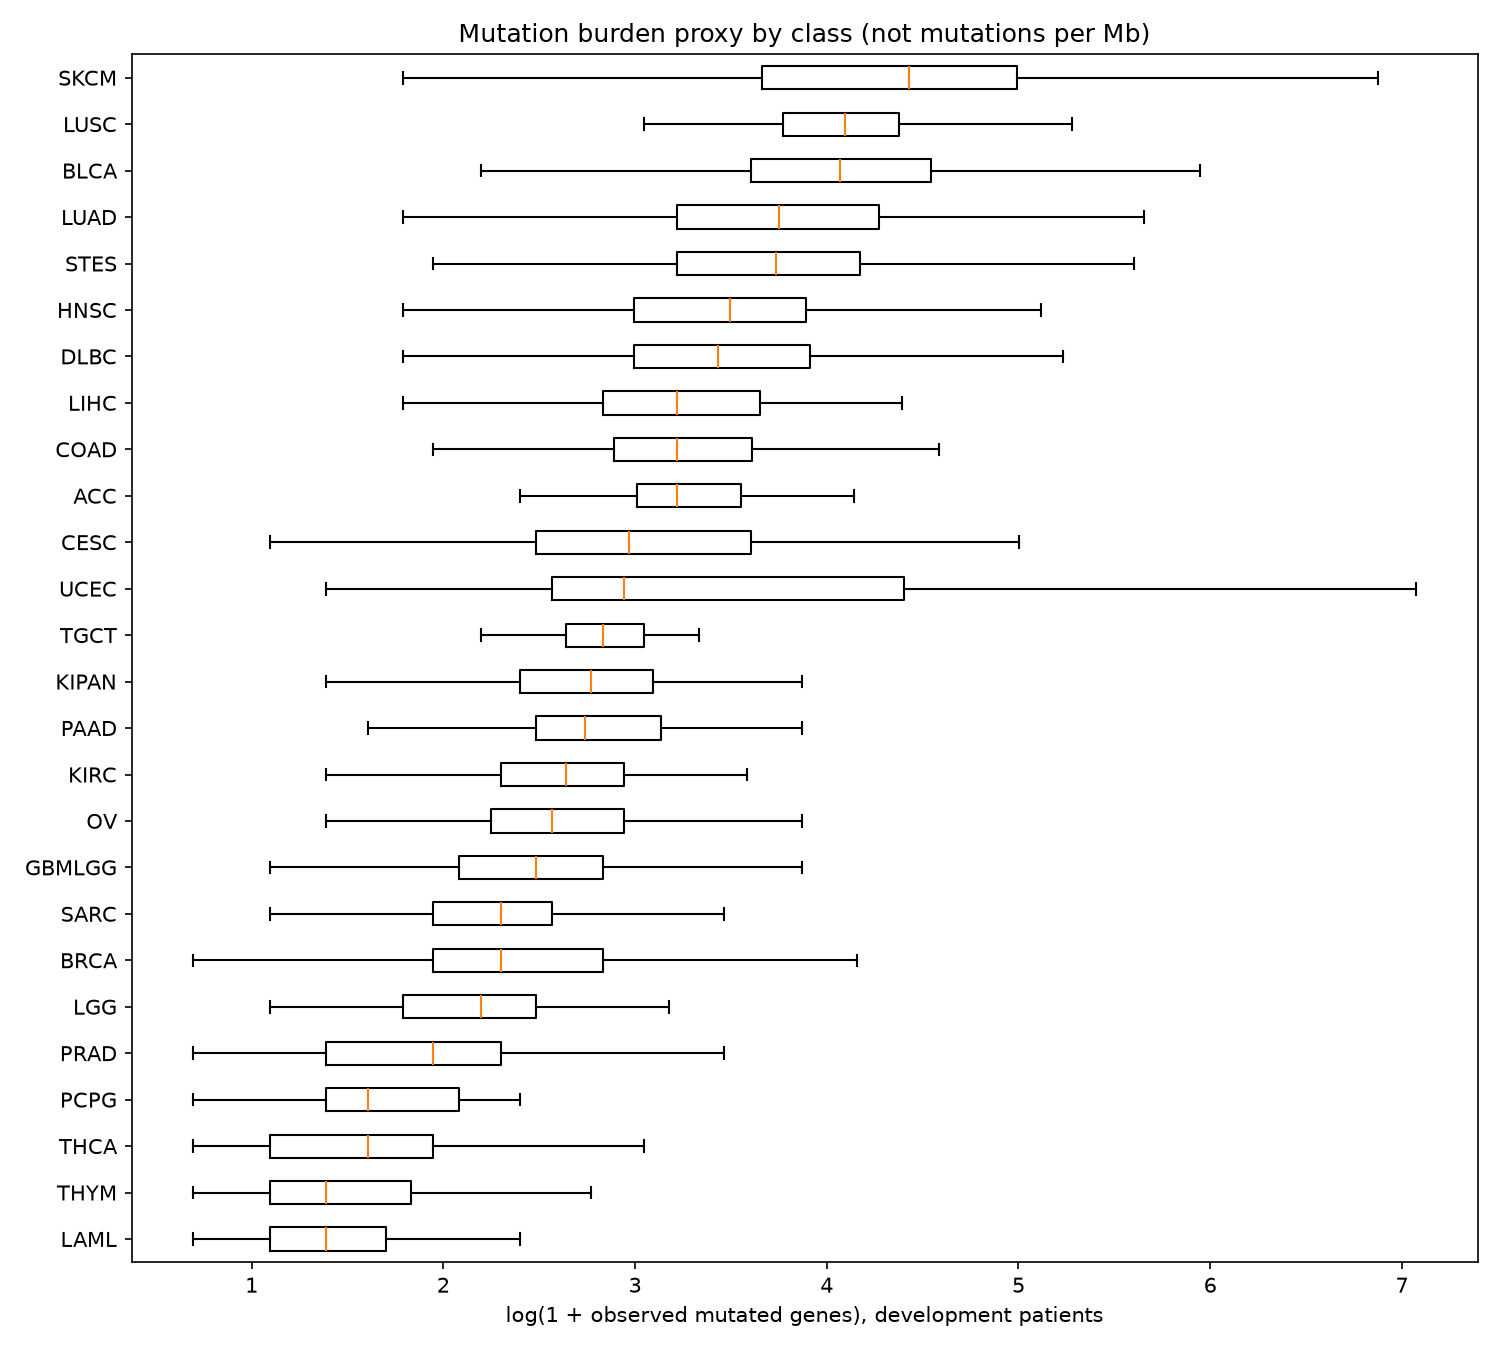

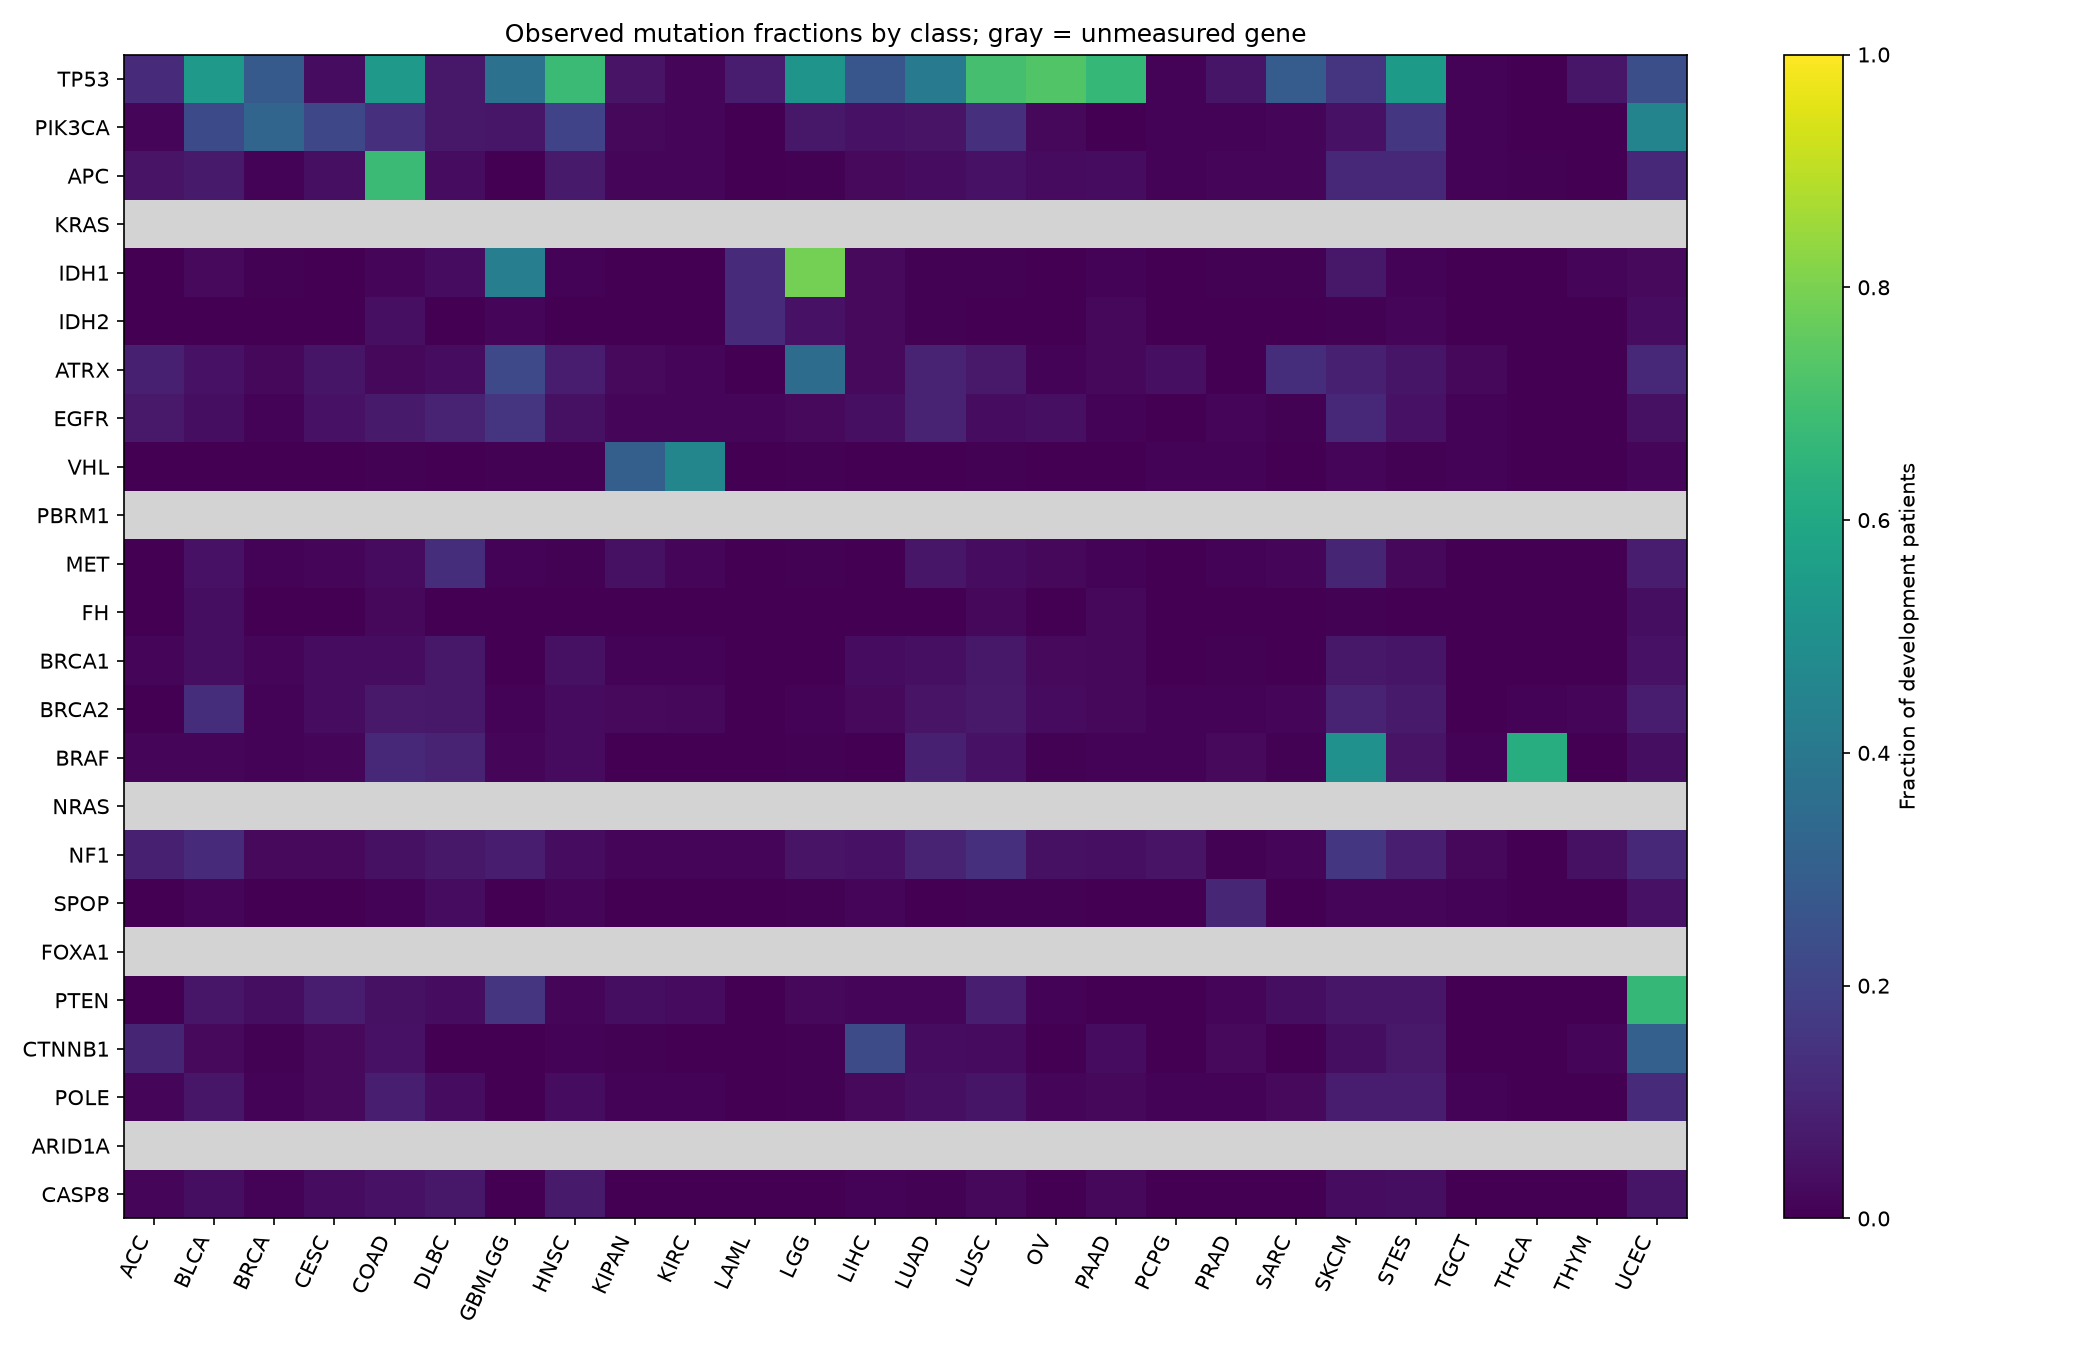

In [7]:
# Archive each train-fitted preprocessing recipe after validation; never use these full fits in CV scores.
preprocessors16={}
for view16 in VIEWS16:
 pre16=final16.pre if view16==finalview16 else Preprocess16(view16).fit(parsed16,yi)
 preprocessors16[view16]=pre16
 with (OUT/f'preprocessor_v16_{view16}.pkl').open('wb') as f:cloudpickle.dump(pre16,f)
 pd.DataFrame({'feature':pre16.names}).to_csv(OUT/f'selected_features_{view16}.csv',index=False)
# A deployable corrected representation exists even when the selected model differs.
newmatrix16=preprocessors16['rare_backoff'].transform(parsed16,training=True)
sparse.save_npz(OUT/'full_train_rare_backoff_matrix.npz',newmatrix16);pd.DataFrame({'ID':train.ID,'SUBCLASS':y}).to_csv(OUT/'full_train_matrix_rows.csv',index=False)
# Meaningful safety check: column scaling must not cancel the intended exact-variant shrinkage.
pre16=preprocessors16['rare_backoff'];check_cols16=[j for j,name in enumerate(pre16.names) if name.startswith('variant:') and 0<pre16.residual_weights[j]<1]
assert check_cols16
for j in check_cols16[:10]:
 values=newmatrix16[:,j].data
 if len(values):assert np.allclose(values,pre16.residual_weights[j],atol=1e-6)
# Annotation change ledger; no raw token is dropped because a parser cannot resolve it.
auditf16=pd.read_csv(OUT/'parser_audit_dev.csv');auditf16['legacy_kind']=auditf16.raw.map(lambda t:kind(canon(t)));auditf16.groupby(['legacy_kind','kind']).agg(unique_tokens=('raw','size'),occurrences=('occurrences','sum')).reset_index().to_csv(OUT/'legacy_new_annotation_comparison.csv',index=False)
family16=[]
for view16,pre16 in preprocessors16.items():
 counts16=Counter(str(name).split(':',1)[0] for name in pre16.names)
 for family16_name,count16 in counts16.items():family16.append(dict(view=view16,family=family16_name,selected_features=count16))
pd.DataFrame(family16).to_csv(OUT/'feature_family_counts.csv',index=False)
coverage16=[]
for panel16,members16 in PANELS16.items():coverage16.append(dict(panel=panel16,paper=panel16.split('_')[0],requested_genes=' '.join(members16),present_genes=' '.join(g for g in members16 if g in genes),unmeasured_genes=' '.join(g for g in members16 if g not in genes)))
pd.DataFrame(coverage16).to_csv(OUT/'panel_coverage.csv',index=False)
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import Image as IPImage
FIG16=WORK/'figures_v16';FIG16.mkdir(exist_ok=True)
edaf16=pd.read_csv(OUT/'eda_development_patients.csv');order16=edaf16.groupby('SUBCLASS').mutated_genes.median().sort_values().index
fig,ax=plt.subplots(figsize=(10,9));ax.boxplot([np.log1p(edaf16.loc[edaf16.SUBCLASS==c,'mutated_genes']) for c in order16],orientation='horizontal',tick_labels=order16,showfliers=False);ax.set_xlabel('log(1 + observed mutated genes), development patients');ax.set_title('Mutation burden proxy by class (not mutations per Mb)');fig.tight_layout();fig.savefig(FIG16/'burden_development.png',dpi=150);plt.close(fig)
markers16=['TP53','PIK3CA','APC','KRAS','IDH1','IDH2','ATRX','EGFR','VHL','PBRM1','MET','FH','BRCA1','BRCA2','BRAF','NRAS','NF1','SPOP','FOXA1','PTEN','CTNNB1','POLE','ARID1A','CASP8'];matrix16=np.full((len(markers16),NC),np.nan)
for i,g in enumerate(markers16):
 if g not in genes:continue
 for j,c in enumerate(labels):
  idx=DEV16[y[DEV16]==c];matrix16[i,j]=sum(any(gg==g for gg,ev in parsed16[k]['mutations']) for k in idx)/max(len(idx),1)
fig,ax=plt.subplots(figsize=(14,9));cm=plt.colormaps['viridis'].copy();cm.set_bad('lightgray');image16=ax.imshow(np.ma.masked_invalid(matrix16),aspect='auto',vmin=0,vmax=1,cmap=cm);ax.set_yticks(np.arange(len(markers16)),markers16);ax.set_xticks(np.arange(NC),labels,rotation=65,ha='right');ax.set_title('Observed mutation fractions by class; gray = unmeasured gene');fig.colorbar(image16,ax=ax,label='Fraction of development patients');fig.tight_layout();fig.savefig(FIG16/'marker_fractions_development.png',dpi=150);plt.close(fig)
display(IPImage(filename=str(FIG16/'burden_development.png')));display(IPImage(filename=str(FIG16/'marker_fractions_development.png')))
print('Preprocessors, corrected train matrix, annotation audit, panels, figures saved. No inference CSV created.',flush=True)


## 논문별 적용 근거와 분석 보고서 생성

In [8]:
# The review registry is embedded in this notebook. No online access is needed to rerun the analysis.
assert len(BIBLIO16)==50 and len({r['doi'] or r['url'] for r in BIBLIO16})==50
review16={r['id']:r for r in BIBLIO16}
def cite16(ids):return ', '.join(f"[{i}]({review16[i]['url']})" for i in ids)
metrics16=json.loads((OUT/'metrics.json').read_text());split16=json.loads((OUT/'split_audit.json').read_text());table16=pd.read_csv(OUT/'comparison.csv');outertable16=pd.read_csv(OUT/'outer_fold_results.csv');class16=pd.read_csv(OUT/'eda_by_class.csv');annotation16=pd.read_csv(OUT/'legacy_new_annotation_comparison.csv');coverage16=pd.read_csv(OUT/'panel_coverage.csv');familytable16=pd.read_csv(OUT/'feature_family_counts.csv');audit16=pd.read_csv(OUT/'parser_audit_dev.csv')
rawstatpath16=OUT/'raw_eda_summary.json';rawstat16=json.loads(rawstatpath16.read_text()) if rawstatpath16.exists() else None
DOC16=WORK/'LITERATURE_REVIEW_AND_PREPROCESSING_V16.md'
lines16=['# 논문 50편 검토와 암종 분류 EDA·전처리 재설계 — v16','', '작성·검색 기준일: **2026-11-10**. 기존 v6·v10을 보존한 별도 연구입니다. test/sample은 열지 않았고 기존 홀드아웃도 점수 계산에 사용하지 않았습니다. 외부 환자·정답 데이터는 추가하지 않았습니다.','', '## 먼저 확인할 결과','',f"- 같은 새 그룹 분할에서 기존 raw 표현의 고정 LR 평균 F1은 **{table16[(table16.view=='legacy_raw')&(table16.algo=='lr')].macro_f1.iloc[0]:.6f}**입니다.",f"- inner CV가 전처리를 선택한 과정의 outer 평균 Macro F1은 **{metrics16['nested_selected_lr_mean_f1']:.6f}**입니다. 개별 outer 최고값을 이 값 대신 쓰지 않습니다.",'- 이 실험은 단순 모델에 대한 전처리 대조입니다. 과거 v10 앙상블과 seed·모델이 달라 직접 우열을 비교할 수 없으며, 새 Public 성능이나 0.60 달성을 주장하지 않습니다.','- 새 파서·전처리기·실험용 LR 모델을 저장했지만 기존 주 모델과 제출 파일은 교체하지 않았습니다.','', '## 1. 문헌을 어떻게 찾고 어디까지 확인했는가','', 'Europe PMC의 DOI/PMID/PMCID 검색과 출판사·PMC 원문을 사용했습니다. 키워드는 somatic mutation / tissue of origin / cancer type classification / rare variant meta-feature / network-based stratification / variant annotation / HGVS / feature-selection leakage / nested cross-validation입니다. 제목·연도·식별자를 대조한 **중복 없는 50편**을 선별했습니다. arXiv와 정식 출판본을 두 편으로 세거나 corrigendum을 독립 근거로 세지 않았습니다.','', '49편은 초록 또는 출판사 초록을 확인했고, 초록이 없는 P45는 공개 본문을 확인했습니다. 공개 XML 원문 캐시는 26편 확보했습니다. **원문 확보는 전체 정독을 뜻하지 않습니다.** 핵심 15편은 방법/중요 본문의 특정 절·발췌를 추가로 검토했습니다. 각 논문 아래의 검토 범위를 구분했습니다. 이는 선별형 근거 검토이며 정식 체계적 문헌고찰·메타분석은 아닙니다.','', 'P34는 최초 DOI가 무관한 lncRNA 논문으로 연결되어 제목 대조 후 올바른 갑상선암 논문으로 교체했습니다. 최종 50편에는 수정된 논문만 포함합니다. `artifacts/v16/literature/excluded_identifier_match.json`에 제외 근거를 남겼습니다. 게재연도는 Europe PMC 기준이며 온라인 선행 게재연도와 다를 수 있습니다.','', '원문/초록 캐시는 연구용 `artifacts/v16/literature/`에만 두고 Git에 포함하지 않습니다. 이 문서에는 원문 복사 대신 직접 작성한 요약·적용·한계를 기록했습니다. 검색에 환자 ID나 환자별 변이 목록을 전송하지 않았습니다.','', '## 2. 논문의 입력과 이 CSV의 입력은 다르다','', '| 정보 | 현재 가용성 | 처리 |','| --- | --- | --- |','| gene별 WT/변이 문자열 | 있음 | 원문을 보존하고 보수적으로 구조화 |','| 단백질처럼 보이는 AA 변화·위치 | 다수 있음 | 표기 기반 속성; 실제 참조 단백질과의 일치 검증은 안 됨 |','| DNA ref/alt·염색체·유전체 좌표·assembly | 없음 | SBS96·genomic 1 Mb bin을 만들지 않음 |','| transcript/isoform·참조 서열 | 없음 | 위치 ±몇 칸 보정·3′ 정규화·isoform 매핑을 하지 않음 |','| CNV·fusion·methylation·RNA·임상 노출 | 없음 | 변이 유무로 가짜 상태를 추정하지 않음 |','| SIFT·PolyPhen·CADD 등 기능 점수 | 없음 | missense/fs 유형에 임의 점수를 대입하지 않음 |','| 분석 대상 exon 길이·시퀀싱 영역 | 없음 | 변이 수를 TMB/Mb라 부르지 않고 유전자 길이를 최대 관측 위치로 추정하지 않음 |','', '논문에서 높은 accuracy를 보고했더라도 WGS·CNV·RNA·암종 수·cohort·평가 지표가 다릅니다. 논문의 점수를 현재 26종 Macro F1의 기대값이나 이론적 상한으로 사용하지 않습니다. 특히 mutation-only와 multi-omics 결과의 차이는 '+cite16(['P01','P02','P06','P07','P09'])+'에서 확인했습니다.','', '## 3. 어떤 근거를 어떤 코드로 옮겼는가','', '| 변경 ID | 구현 또는 판단 | 근거 | 원문 재현과의 차이 |','| --- | --- | --- |', '| M01 | `parse_token16`, `parse_rows16`: 원문 보존·표기 분리·미해석/불확실성 기록 | '+cite16(['P41','P42','P43'])+' | 완전한 HGVS validator/annotation tool 아님 |','| M02 | gene/type count·raw/unique event 수·변이량·동의 채널 유지 | '+cite16(['P04','P06','P17','P19','P20'])+' | TMB·dN/dS·MutSigCV가 아닌 관측값 |','| M03 | exact residual + 공유 gene/type/AA metadata + train DF 기반 희귀 back-off | '+cite16(['P05','P09','P10'])+' | 계층 Bayesian/group-lasso·attention·NMF의 재현 아님; 제한된 입력에 대한 자체 적응 |','| M04 | 논문별 작은 gene panel 합계의 별도 ablation | '+cite16(['P11','P13','P14'])+' 및 P25~P40 | 실제 구성원은 아래 명시한 TCGA 부분집합; PPI/network propagation이 아님 |','| M06 | ID 제외·test open 차단·그룹 분리·inner 선택/outer 평가 | '+cite16(['P47','P48','P49','P50'])+' | 3×2 nested group CV; 과거 관찰 편향까지 제거하지는 못함 |','| M07 | 고정 LR 및 ExtraTrees 대조 | '+cite16(['P03','P07'])+' | 저자의 RF 선별이나 모델 전체를 복제한 것이 아님 |','', 'M03의 exact 변이 감쇠는 `df/(df+5)`라는 명시적 휴리스틱입니다. **MaxAbs 이후** 해당 residual 열에 적용해 column scaling이 감쇠를 상쇄하지 않도록 확인했습니다. gene/type/AA 공유 특징은 남겨 희귀·미관측 exact 변이도 가능한 일반 정보에 기여하게 합니다. training 희귀 요약에는 자기 자신을 뺀 DF를 쓰고, 검증/추론에는 학습 DF만 씁니다. 이 값은 posterior나 병원성 점수가 아닙니다.','', '## 4. 새 파서의 범위와 검증 사례','', '| 입력 예 | 해석 | 지키는 경계 |','| --- | --- | --- |','| `R132H` / `R132R` | missense / synonymous | 기능적 유해성은 판정하지 않음 |','| `R213*` / `*363*` / `*213Q` | stop gained / retained / lost | 별표가 있다는 이유로 전부 stop gained로 묶지 않음 |','| `K16Rfs*23` | 영향 위치 16, 새 reading-frame 종료 거리 23 | 23을 변이 위치로 쓰지 않음 |','| `1_2FS>FS` | 길이가 일치하는 synonymous block | 대문자 AA `FS`를 소문자 frameshift `fs`로 읽지 않음 |','| `483_484MP>IA` | 두 AA 성분 속성, 원래 복합 event는 1개로 보존 | 독립 DNA 사건 두 개라고 단정하지 않음 |','| `10_12AAA>DD` | 길이 불일치 complex range | 임의 분해·위치 이동을 하지 않음 |','| `p.(Arg123His)` | 불확실성 표시 + 구조화 AA 변화 | 추정 표기 괄호를 확정 관측과 합치지 않음 |','| `R123X` | ambiguous residue/X 플래그 | X를 무조건 stop으로 바꾸지 않음 |','| `A391` / 미해석 토큰 | 불완전/원문 보존 | 버리거나 정답을 추정하지 않음 |','| WT / 결측 | 서로 다른 상태 | 결측을 WT로 대입하지 않음 |','', '15개 표기 fixture와 결측·중복 검사 사례를 통과했습니다. 이 파서는 데이터의 단백질형 문법을 해석하는 보수적 구현입니다. 참조 서열 검증을 한 정식 HGVS 변환기가 아니며, bare `490del` 같은 legacy 위치는 데이터의 단백질형 문맥을 가정한 인덱스입니다. protein bin 64/256은 공학적 구간이며 실제 단백질 domain·유전자 길이·유전체 구간이 아닙니다.','', '기존 표기 분류와의 변경 기록:','', annotation16.to_markdown(index=False), '', '## 5. EDA 범위와 실제 관찰','',f"공식 train은 {len(train):,}명·{len(genes):,}개 gene 컬럼이며, 이전 홀드아웃 {split16['old_holdout_rows']:,}명은 점수 계산에서 제외했습니다. EDA와 교차검증은 개발 {split16['development_rows']:,}명만 사용했습니다. 새 canonical grouping 때문에 제외한 개발 환자는 {len(split16['excluded_development_rows'])}명입니다. 원본/새 정규화 동일 프로필을 union하여 같은 그룹이 양쪽 fold에 걸치지 않게 했습니다.", '', class16.to_markdown(index=False),'', '![개발 환자의 관측 변이량](figures_v16/burden_development.png)','', '동일 변이 프로필에서 여러 라벨이 나타나는 경우를 곧바로 오표기 환자라고 단정하지 않았습니다. 서로 다른 암이 같은 관측 변이를 가질 수 있고 추가 임상 정보가 없을 수도 있습니다. 다수결 relabel이나 어려운 환자 제거로 점수를 올리지 않았습니다. 저변이 환자도 평가에 남겼습니다.','', '![문헌 마커의 데이터 내 관측 비율](figures_v16/marker_fractions_development.png)','', 'heatmap은 현재 개발 데이터의 관측 빈도이며 논문의 유병률이나 확정 진단 기준이 아닙니다. 측정 컬럼이 없는 gene은 0/WT 대신 unmeasured로 구분했습니다. GBMLGG/LGG, KIPAN/KIRC 및 STES/STAD·COAD/COADREAD 등의 명칭 관계는 데이터 사전 확인 과제로 남기고 라벨을 바꾸지 않았습니다.','', '## 6. 논문 유전자 부분집합과 실제 측정 범위','',coverage16.to_markdown(index=False),'', '이 목록은 각 논문에 명시된 일부 mutation gene을 고정한 수동 사전지식입니다. 저자의 전체 pathway·driver 목록을 복제하지 않았습니다. IDH/RAS 계열을 IDH1/IDH2 및 NRAS/HRAS/KRAS로 펼친 것은 명시적 구현 선택입니다. HGNC alias를 추측해 컬럼을 합치지 않았습니다. 입력은 관측 mutation count뿐이며 경로 활성·임상 아형·fusion/CNV·methylation을 의미하지 않습니다. `truncation_notation_genes`라는 기존 변수명은 실제로 stop/fs/deletion/delins 표기를 합한 값이라 in-frame 변경도 포함할 수 있으며 기능 상실의 확정 판정이 아닙니다.','', '외부에서 사용한 것은 방법과 고정 gene 사전지식이며 외부 환자 행이나 정답은 추가하지 않았습니다. 문헌의 TCGA cohort와 이 CSV 원천의 환자 중복 여부는 확인할 수 없어 독립 외부 코호트라고 주장하지 않습니다.','', '## 7. 전처리 선택과 검증','', '4개 view는 legacy_raw / hierarchical / rare_backoff / rare_backoff_panels입니다. 표기 구조화·이벤트 count를 먼저 비교하고, 희귀 back-off 및 고정 panel 추가를 순서대로 분리했습니다. 모든 DF·어휘·chi2 최대 4096개·MaxAbs는 해당 inner 또는 outer 학습 부분에서만 적합했습니다. 전처리 view 선택은 inner 2-fold의 고정 LR(C=0.1)로 하며 outer 3-fold(seed 16016)에서 선택 과정을 평가했습니다. ExtraTrees는 200개·depth20·leaf2의 고정 대조군입니다. outer 검증으로 조기 종료하거나 다시 선택하지 않았습니다.','', '각 고정 view의 outer 대조(탐색적 ablation):','',table16.to_markdown(index=False),'', '선택 과정을 평가한 nested LR 결과:','',pd.DataFrame({'fold':range(3),'macro_f1':metrics16['nested_selected_lr_fold_f1']}).to_markdown(index=False),'',f"nested fold 평균은 **{metrics16['nested_selected_lr_mean_f1']:.6f}**, 전체 OOF를 합친 pooled F1은 **{metrics16['nested_selected_lr_pooled_f1']:.6f}**입니다. 두 값은 평균 방식이 다릅니다. 최종 배포 실험용 view `{metrics16['final_view_from_inner_selection']}`는 inner 선택의 다수결/inner 평균으로 정했고 outer 최고 view로 바꾸지 않았습니다.",'', '외부 panel이 모든 알고리즘을 개선하지는 않았습니다. LR에서는 panel 없는 back-off가 탐색 평균에서 조금 높고, 트리에서는 panel이 도움이 됐습니다. 논문상 타당성이 곧 이 데이터의 성능 개선을 보장하지 않습니다. 더구나 이미 개발 데이터를 여러 버전에서 관찰해 온 연구자 선택 편향은 nested CV만으로 소급 제거되지 않습니다.','', '## 8. 실제 입력 변수와 저장 상태','',familytable16.to_markdown(index=False),'', '원본 raw와 새 해석 결과는 `parser_audit_dev.csv`로 대조할 수 있습니다. 정확한 최종 선택 목록은 `artifacts/v16/selected_features_<view>.csv`, 기본 선택은 `final_selected_features.csv`입니다.','', '- `preprocessor_v16_<view>.pkl`: 4개 전처리기를 공식 train 전체로 재적합한 보관본.','- `preprocessor_v16.pkl`, `cancer_model_v16_experimental.pkl`: inner 선택으로 정한 실험용 LR pipeline.','- `full_train_rare_backoff_matrix.npz`: 전체 train용 새 back-off 표현. 행 ID/라벨은 `full_train_matrix_rows.csv`, 열은 해당 view의 selected_features 파일.','- 전체-train 재적합본은 위 CV 점수를 계산하는 데 사용하지 않았습니다. training 행렬의 희귀 요약은 자기 자신 제외 규칙을 쓰므로 inference-role transform과 일부 값이 다릅니다.','- 신규 test 추론·제출 CSV·Public 점수는 없습니다. 기존 v6·v10 파일을 변경하지 않았습니다.','', '전체 train에 적합한 저장 행렬을 다시 분할해 CV를 계산하면 누수가 생깁니다. 이 행렬은 최종 학습 보관용이며, 새 검증에서는 반드시 각 fold의 학습 부분만으로 전처리기를 다시 적합해야 합니다. 점별 문자열 파싱과 동일 프로파일 그룹 형성은 고정 규칙이고, 빈도·어휘·스케일·변수 선택은 fold 안에서만 학습합니다.\n\n## 9. 실행과 근거 파일','', '`cencer_v16.ipynb`에 파서·EDA·inner/outer 학습·전처리 저장·이 보고서 생성을 모두 포함했습니다. `requirements-v16.txt` 환경과 `data/train.csv`만 있으면 실행합니다. 문헌 메타데이터/직접 작성한 검토 요약은 노트북 안에도 고정해 재실행 시 네트워크가 필요하지 않습니다. 논문 원문은 코드 실행 의존성이 아닙니다.','', '아래의 논문별 기록은 **실제로 가져온 것과 가져오지 않은 것**을 구분합니다. 적용 태그 M01/M02/M03/M04/M06/M07는 3절, X01은 입력 부재, X02는 길이/영역 부재, X03은 기능 점수/참조 정보 부재, X04는 외부 네트워크 알고리즘 미재현을 뜻합니다.','', '## 10. 논문 50편별 분석·적용·한계','']
for r16 in BIBLIO16:
 title16=r16['title'].rstrip('.')
 lines16.extend([f"### {r16['id']}. [{title16}]({r16['url']})",'',f"{r16['year']} · {r16['short_author']} · 검토 범위: {r16['scope']}",'',f"- 내용: {r16['finding']}",f"- 참고·적용: {r16['use']}",f"- 미적용·한계: {r16['limit']}",'- 연결: '+', '.join(r16['tags']),''])
DOC16.write_text('\n'.join(lines16)+'\n')
assert forbidden_attempts16==[]
proof16={'status':'passed','version':16,'reviewed_unique_papers':50,'review_registry_embedded':True,'fulltext_xml_available':sum(bool(r.get('fulltext_downloaded')) for r in BIBLIO16),'review_depth_disclosed':True,'parser_fixtures_passed':len(FIXTURES16),'nested_selected_lr_mean_f1':metrics16['nested_selected_lr_mean_f1'],'test_opened':False,'sample_opened':False,'holdout_scored':False,'submission_created':False,'external_patient_data_added':False,'forbidden_attempts':forbidden_attempts16,'train_sha256':metrics16['data_sha256'],'final_view':finalview16,'model_saved':True,'all_preprocessors_saved':True,'preprocessing_selection_inside_inner_cv':True}
(OUT/'verification.json').write_text(json.dumps(proof16,indent=2));print('Research report written:',DOC16);print(json.dumps(proof16,indent=2))


Research report written: /Users/mac/project/cancer_project/LITERATURE_REVIEW_AND_PREPROCESSING_V16.md
{
  "status": "passed",
  "version": 16,
  "reviewed_unique_papers": 50,
  "review_registry_embedded": true,
  "fulltext_xml_available": 26,
  "review_depth_disclosed": true,
  "parser_fixtures_passed": 15,
  "nested_selected_lr_mean_f1": 0.39050540773928494,
  "test_opened": false,
  "sample_opened": false,
  "holdout_scored": false,
  "submission_created": false,
  "external_patient_data_added": false,
  "forbidden_attempts": [],
  "train_sha256": "92418b8441d058cfc68e939dd88725610750be4bc8edc51253cffc72fc4fc0ab",
  "final_view": "rare_backoff_panels",
  "model_saved": true,
  "all_preprocessors_saved": true,
  "preprocessing_selection_inside_inner_cv": true
}


## 선택 실행: 사용자 승인 최종 제출 추론
이 셀부터는 test/sample을 **최종 추론에만** 사용합니다. 앞선 문서·지표의 test 미사용은 학습·선별·검증 단계에 대한 기록입니다. 이 셀은 재학습·튜닝하지 않고 저장 모델로 제출 CSV를 만듭니다. 연구용 open guard는 유지하고 별도 추론 프로세스를 사용합니다. 기존 제출 파일과 결과가 다르면 덮어쓰지 않습니다. 저장 모델이 있으면 이 셀만 별도 실행할 수 있습니다. v18 파일은 스트레스 조건 성능 저하가 있는 후속 실험용이며, v19와 구분하세요.

In [ ]:
# 사용자 승인 최종 제출 추론: 학습/검증 단계와 구분합니다.
from pathlib import Path
import subprocess,sys
roots_export=[Path.cwd(),*Path.cwd().parents]
repo_export=next((p for p in roots_export if (p/'data'/'test.csv').is_file()),None)
if repo_export is None:raise FileNotFoundError('공식 data/test.csv와 sample_submission.csv가 필요합니다.')
work_export=repo_export/'models'/'혜진' if (repo_export/'models'/'혜진').is_dir() else repo_export
model_export=work_export/'artifacts'/'v16'/'cancer_model_v16_experimental.pkl'
if not model_export.is_file():raise FileNotFoundError('앞선 학습 셀에서 저장한 모델이 필요합니다.')
# 연구 단계 open guard가 설치된 부모와 구분해 새 추론 프로세스에서만 test를 읽습니다.
# fit/선별/파라미터 변경 없이 저장 모델의 predict만 호출합니다.
inference_program="from pathlib import Path\nimport sys,json,cloudpickle,numpy as np,pandas as pd,hashlib\nfrom threadpoolctl import threadpool_limits\nthreadpool_limits(2)\nmodelpath,testpath,samplepath,outpath,labelpath=map(Path,sys.argv[1:6])\nwith modelpath.open('rb') as f:model=cloudpickle.load(f)\ntest=pd.read_csv(testpath);sample=pd.read_csv(samplepath)\nassert list(sample.columns)==['ID','SUBCLASS'] and test.ID.is_unique and sample.ID.is_unique and set(test.ID)==set(sample.ID)\nx=test.drop(columns=['ID'])\nif isinstance(model,dict):\n classes=np.asarray(model['classes']);predict=lambda frame:model['predict'](model,frame)\nelse:\n with np.load(labelpath,allow_pickle=True) as q:classes=np.asarray(q['labels']).astype(str)\n predict=model.predict_frame\np=np.asarray(predict(x));assert p.shape==(len(test),len(classes)) and len(classes)==26 and np.isfinite(p).all() and (p>=-1e-8).all() and np.allclose(p.sum(1),1,atol=1e-5)\nassert np.allclose(predict(x.iloc[:8]),p[:8],atol=1e-6)\nresult=sample.copy();result.SUBCLASS=result.ID.map(pd.Series(classes[p.argmax(1)],index=test.ID))\nassert result.ID.equals(sample.ID) and not result.isna().any().any()\npayload=result.to_csv(index=False).encode('utf-8');outpath.parent.mkdir(exist_ok=True,parents=True)\nif outpath.exists():\n assert outpath.read_bytes()==payload,'기존 제출 파일과 다릅니다. 파일을 확인하고 별도 이름을 지정하세요.'\nelse:outpath.write_bytes(payload)\nassert pd.read_csv(outpath).equals(result)\nproof={'rows':len(result),'test_use':'inference only','training_performed':False,'sample_id_order':'verified','probabilities':'verified','batch_invariance':'passed','model_sha256':hashlib.sha256(modelpath.read_bytes()).hexdigest(),'csv_sha256':hashlib.sha256(payload).hexdigest()}\nproofpath=modelpath.parent/'submission_inference_verification.json';proofpath.write_text(json.dumps(proof,ensure_ascii=False,indent=2));print(str(outpath));print(json.dumps(proof,ensure_ascii=False,indent=2))\n"
result_export=subprocess.run([sys.executable,'-c',inference_program,str(model_export.resolve()),str((repo_export/'data/test.csv').resolve()),str((repo_export/'data/sample_submission.csv').resolve()),str((repo_export/'submission'/'혜진_submission_v16_experimental.csv').resolve()),str((work_export/'artifacts/v16/oof_probabilities.npz').resolve())],capture_output=True,text=True)
if result_export.returncode:raise RuntimeError(result_export.stderr)
print(result_export.stdout)
